# Anatomy of a Date — Reproducible Machine Learning Research


## Executive Summary

**What problem were we solving?** We studied which features of a blind-date experience correspond to an individual's or both partners' stated interest in another date, and whether repeatable experience profiles are visible.

**What did we do?** We audited 9,084 participant reports about 4,542 dates, checked reciprocal pairing, performed exploratory and statistical analysis, trained models with participant-network-disjoint validation, and compared K-Means with GMM for individual and paired experiences.

**What did we find?** Ratings of enjoyment, attraction, and perceived compatibility are strongly related to stated second-date interest. Participant-disjoint supervised models achieved historical final-test ROC-AUC around 0.94; exploratory clustering distinguished favorable versus unfavorable experiences and uneven partner impressions. Actual numbers are regenerated below.

**What does it mean for a client?** Post-date ratings can help researchers summarize *expressed* dating intentions. They cannot reliably rank strangers before meeting or establish what causes attraction.

**What should be done next?** Validate findings in a new, consented cohort; test strictly pre-date features separately; assess the stability of clusters under participant-disjoint refitting before operational deployment.

**Main limitations:** Observational sample and post-date measurement overlap, repeated participation, one historically accessed holdout, no external replication, and incomplete crossed-participant mixed-effects/EBM investigations.

## Problem Statement and Project Objectives

**Problem.** Romantic interest can be asymmetric, and the unit of analysis changes between one person's evaluation and the paired outcome of a date. Simple row-random model splits risk exposing the same participants to both training and testing.

**Objectives.** (1) establish trustworthy paired data; (2) describe patterns and test pre-stated associations; (3) estimate how well post-date ratings discriminate stated interest without participant overlap; (4) explore experience profiles using outcomes withheld during clustering; and (5) translate findings and limits into research-usable interpretations.

**Research boundary.** This is retrospective prediction and association analysis. It is not causal inference, a pre-date matchmaking engine, or a validated individual decision tool.

## Environment, Data Sources, and Reproducibility Contract

**Single permitted research-data input:** `Dating Dataset(1).zip` (edit `DATA_ZIP_PATH` in the next cell if stored elsewhere). Inside the archive are the original study tables; the code inspects archive contents rather than requiring any exported CSV.

**Environment:** Python, pandas, NumPy, SciPy, scikit-learn, matplotlib, statsmodels, CatBoost, XGBoost, IPython and Jupyter. Install missing packages in your environment before running. Consistent random seeds and package versions are shown in executable cells.

**Execution:** restart kernel → Run All. All intermediate outputs, model objects, predictions, and figure data live in notebook memory. Do not use the historically accessed holdout to redesign hyperparameters or thresholds.

**Documentation standard:** For each substantive experiment, interpret *Purpose → Method/Code → Output → Inference → Decision*. Model comparison tables and reported metrics must originate from executed outputs. Save the completed notebook after execution to retain the audit trail.

In [1]:
from pathlib import Path
import os, sys
# Edit ONLY DATA_ZIP_PATH if the original research archive is stored elsewhere.
DATA_ZIP_PATH = Path('Dating Dataset(1).zip')
assert DATA_ZIP_PATH.is_file(), f'Original dataset ZIP not found: {DATA_ZIP_PATH}'
PROJECT_ROOT = DATA_ZIP_PATH.parent
print('Raw dataset:', DATA_ZIP_PATH.resolve())
print('Python:', sys.version.split()[0])


Raw dataset: /mnt/data/Dating Dataset(1).zip
,Python: 3.13.5


## Stage 1 — Data Preparation and Quality Assessment

**Purpose.** Establish valid records, units of analysis and honest missingness flags before statistical comparisons or modeling.

**Method.** Read the original ZIP; inspect schema, counts, types, missing values and label availability; verify paired reports; flag ambiguous dates/formats and duration disagreements instead of silently treating missing comparisons as agreements.

**Output and decision.** Preserve one individual-report table and one pair-level table in notebook memory. Do not feed identifiers, targets or post-outcome variables into predictors.

In [2]:
import zipfile, io, pandas as pd, numpy as np
zpath=DATA_ZIP_PATH
with zipfile.ZipFile(zpath) as z:
    files=[x for x in z.infolist() if not x.is_dir()]
    assert z.testzip() is None, 'Corrupt ZIP member'
    print('ZIP files:');display(pd.DataFrame([{'filename':x.filename,'bytes':x.file_size} for x in files]))
    for x in files:
        if x.filename.lower().endswith('.csv'):
            try:
                t=pd.read_csv(io.BytesIO(z.read(x.filename)))
                print(x.filename,'shape',t.shape,'columns',list(t.columns[:8]))
            except Exception as e:print('CSV inspection warning:',x.filename,str(e)[:180])
print('Decision: rely on M2 schema and reciprocal-ID checks for final row-level integrity.')

ZIP files:


,filename,bytes
0,Data/Study 1/DateTypePredictions_Data.csv,86493
1,Data/Study 2/DateTypeReality_Data.csv,1000389
2,Materials/Study 1/DateTypePredictions_SurveyFl...,162793
3,Materials/Study 2/QuestionnairesAllFourFinal.xlsx,27550
4,Preregistration/Study 1/DateTypeExpectationsPr...,19226


Data/Study 1/DateTypePredictions_Data.csv shape (200, 82) columns ['StartDate', 'EndDate', 'Status', 'IPAddress', 'Progress', 'Duration (in seconds)', 'Finished', 'RecordedDate']
,Data/Study 2/DateTypeReality_Data.csv shape (9084, 32) columns ['MatchId', 'user_id', 'partner_id', 'Date', 'OverallRating', 'OverallRatingNum', 'SecondDate', 'SecondDate_YES']
,Decision: rely on M2 schema and reciprocal-ID checks for final row-level integrity.


### Environment and source acquisition

**Purpose.** Load the original research archive without modifying source files.

**Method.** Verify ZIP integrity, locate the Study 2 CSV, and inspect a few records. The notebook expects `Dating Dataset(1).zip` in the same folder.

**Expected output.** The raw table dimensions and three example observations. No preprocessing is applied here.

**Decision rule.** Stop if the ZIP is missing, corrupt, or the expected CSV cannot be read.

In [3]:
from pathlib import Path
import io, zipfile
import numpy as np
import pandas as pd

ZIP_PATH = DATA_ZIP_PATH
SOURCE_MEMBER = 'Data/Study 2/DateTypeReality_Data.csv'
assert ZIP_PATH.exists(), f'Missing source archive: {ZIP_PATH.resolve()}'
with zipfile.ZipFile(ZIP_PATH) as archive:
    assert archive.testzip() is None, 'ZIP integrity check failed'
    raw = pd.read_csv(io.BytesIO(archive.read(SOURCE_MEMBER)))
print('Raw shape:', raw.shape)
display(raw.head(3))

Raw shape: (9084, 32)


,MatchId,user_id,partner_id,Date,OverallRating,OverallRatingNum,SecondDate,SecondDate_YES,Enjoy,Attract,Great,PSAnx,PSAvoid,SafeHav,SecBase,DateLength,DateLengthClean,DateType,PI1,PI2,PI3,PI4,PI5,PI6,PI7,PI8,PI9,PI10,PI11,PI12,PI13,PI14
0,2017494,900564,2525869,20-Dec-23,Good,4.0,yes,1.0,4.0,4.0,3.0,3.0,4.0,3.0,3.0,0:25 minutes,0.42,zoom,4.0,NaN,NaN,NaN,NaN,4.0,NaN,NaN,4.0,NaN,4.0,NaN,4.0,NaN
1,1956083,1367909,3765149,8-Nov-23,Awful,1.0,no,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,25 min,0.42,zoom,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1849830,3746502,895001,24-Oct-23,Bad,2.0,no,0.0,3.0,1.0,1.0,3.0,4.0,3.0,2.0,25 min,0.42,zoom,1.0,1.0,4.0,4.0,NaN,2.0,NaN,4.0,4.0,NaN,NaN,NaN,4.0,NaN


### Interpretation and decision

**Output interpretation.** Check that the source loads as a participant-report table (expected: 9,084 rows, 32 columns). The first rows are a schema preview, not a representative sample.

**Decision.** Keep `raw` untouched; all transformations operate on a copy.

### Schema, valid ranges, and missingness

**Purpose.** Detect impossible ratings, malformed identifiers, invalid targets, and unreadable dates before further analysis.

**Method.** Assert that ratings lie within 1–5, the decision label is binary, identifiers are present, and date strings parse. Normalize date-format text without overwriting original values.

**Expected output.** Format frequencies, exact-duplicate count, and the twelve most incomplete columns.

**Decision rule.** Invalid critical values trigger an assertion instead of silent coercion; missing survey answers remain missing.

In [4]:
df = raw.copy(deep=True)
ID_COLS = ['MatchId', 'user_id', 'partner_id']
RATINGS = ['OverallRatingNum','Enjoy','Attract','Great','PSAnx','PSAvoid','SafeHav','SecBase'] + [f'PI{i}' for i in range(1,15)]
for col in ID_COLS:
    assert df[col].notna().all(), f'Null ID: {col}'
for col in RATINGS + ['SecondDate_YES','DateLengthClean']:
    df[col] = pd.to_numeric(df[col], errors='raise')
for col in RATINGS:
    assert df[col].dropna().between(1,5).all(), f'Out-of-range rating: {col}'
assert df['SecondDate_YES'].dropna().isin([0,1]).all()
df['date_parsed'] = pd.to_datetime(df['Date'], format='%d-%b-%y', errors='coerce')
assert df['date_parsed'].notna().sum() == df['Date'].notna().sum(), 'Unparseable dates'
df['date_type_normalized'] = df['DateType'].astype('string').str.strip().str.lower()
print('Date types:', df['date_type_normalized'].value_counts(dropna=False).to_dict())
print('Exact duplicates:', int(df.duplicated().sum()))
print('Missing values (top 12):')
display(df.isna().sum().sort_values(ascending=False).head(12).to_frame('missing'))

Date types: {'in-person': 7499, 'zoom': 1541, 'other': 28, <NA>: 16}
,Exact duplicates: 0
,Missing values (top 12):


,missing
PI12,5168
PI8,5062
PI6,4948
PI10,4934
PI2,4850
PI7,4835
PI3,4819
PI11,4805
PI5,4796
PI4,4779


### Interpretation and decision

**Output interpretation.** A high missing count in optional `PI1`–`PI14` items does not mean the whole observation is unusable. Review missingness by analysis objective, not by blanket row deletion.

**Decision.** No imputation or automatic dropping at this stage. Data types are standardized only where justified.

### Reciprocal match integrity

**Purpose.** Establish that each date contains two distinct, reciprocally identified respondents.

**Method.** Check two reports per `MatchId`, unique participant-match pairs, no self-matches, and reciprocal `user_id`/`partner_id` values.

**Expected output.** Number of verified pairs.

**Decision rule.** Fail immediately if the pairing structure is inconsistent: mutual-interest analysis would otherwise be invalid.

In [5]:
assert df.groupby('MatchId').size().eq(2).all(), 'Some matches do not have two reports'
assert df[['MatchId','user_id']].duplicated().sum() == 0, 'Repeated participant within a match'
assert (df['user_id'] != df['partner_id']).all(), 'Self-match detected'
pairs = df.sort_values(['MatchId','user_id']).copy()
left = pairs.groupby('MatchId').nth(0).reset_index()
right = pairs.groupby('MatchId').nth(1).reset_index()
assert left['MatchId'].equals(right['MatchId'])
assert ((left['user_id'].to_numpy() == right['partner_id'].to_numpy()) &
        (left['partner_id'].to_numpy() == right['user_id'].to_numpy())).all(), 'Nonreciprocal partner IDs'
print('Reciprocal matches verified:', len(left))

Reciprocal matches verified: 4542


### Interpretation and decision

**Output interpretation.** Successful reciprocal checks support constructing one row per date. They do **not** establish that the two people agreed about the date or its duration.

**Decision.** Retain participant identifiers for leakage-safe grouping, but never treat them as predictive numerical features.

### Row-level quality flags

**Purpose.** Preserve questionable observations while making their limitations explicit.

**Method.** Flag missing/nonpositive duration, duration above 6 or 12 hours, optional-questionnaire completion, and missing second-date decisions. Cross-check text and numeric decision fields.

**Expected output.** Counts for each quality flag.

**Decision rule.** Flag, do not automatically winsorize or discard, plausible extreme durations. A later sensitivity analysis can assess their influence.

In [6]:
df['duration_missing'] = df['DateLengthClean'].isna()
df['duration_nonpositive'] = df['DateLengthClean'].notna() & (df['DateLengthClean'] <= 0)
df['duration_over_6h'] = df['DateLengthClean'] > 6
df['duration_over_12h'] = df['DateLengthClean'] > 12
df['pi_answered_count'] = df[[f'PI{i}' for i in range(1,15)]].notna().sum(axis=1)
df['pi_any_answered'] = df['pi_answered_count'] > 0
df['second_date_missing'] = df['SecondDate_YES'].isna()
label = df['SecondDate'].astype('string').str.strip().str.lower()
known = label.isin(['yes','no']) & df['SecondDate_YES'].notna()
assert (label[known].eq('yes').astype(int).to_numpy() == df.loc[known,'SecondDate_YES'].astype(int).to_numpy()).all(), 'Target text/numeric conflict'
print(df[['duration_missing','duration_nonpositive','duration_over_6h','duration_over_12h','pi_any_answered','second_date_missing']].sum())

duration_missing         109
,duration_nonpositive       0
,duration_over_6h          31
,duration_over_12h          2
,pi_any_answered         4914
,second_date_missing       13
,dtype: int64


### Interpretation and decision

**Output interpretation.** These are *report-level* counts, not counts of unique dates. Optional questionnaire nonresponse is expected and should be examined before using the PI features.

**Decision.** Keep raw measurements and add flags for transparent downstream filtering.

### Build the match-level analysis table

**Purpose.** Represent both partners in one record so we can study mutual interest and disagreement.

**Method.** Sort within each match, preserve both reports in `a_` and `b_` columns, compute disagreement flags, and define mutual second-date interest only when both decisions are observed.

**Expected output.** Match-level dimensions, discrepancy counts, and mutual-interest distribution.

**Decision rule.** Do not infer missing second-date choices. Consensus format is assigned only when both respondents explicitly agree on an eligible category.

In [7]:
# Rebuild aligned rows after quality flags were added.
pairs = df.sort_values(['MatchId','user_id'])
a = pairs.groupby('MatchId').nth(0).reset_index()
b = pairs.groupby('MatchId').nth(1).reset_index()
assert a['MatchId'].equals(b['MatchId'])
match = pd.DataFrame({'MatchId': a['MatchId']})
for slot, part in [('a',a),('b',b)]:
    for col in ['user_id','partner_id','date_parsed','date_type_normalized','DateLengthClean',
                'SecondDate_YES','OverallRatingNum','Enjoy','Attract','Great','pi_answered_count']:
        match[f'{slot}_{col}'] = part[col].to_numpy()
match['date_disagreement'] = (match['a_date_parsed'].notna() & match['b_date_parsed'].notna() &
                              match['a_date_parsed'].ne(match['b_date_parsed']))
match['date_gap_days'] = (match['a_date_parsed']-match['b_date_parsed']).abs().dt.days
match['format_disagreement'] = (match['a_date_type_normalized'].notna() &
                                match['b_date_type_normalized'].notna() &
                                match['a_date_type_normalized'].astype('string').ne(match['b_date_type_normalized'].astype('string')).fillna(False))
match['format_incomplete'] = (match['a_date_type_normalized'].isna() | match['b_date_type_normalized'].isna())
match['date_type_consensus'] = match['a_date_type_normalized'].where(
    match['a_date_type_normalized'].astype('string').eq(match['b_date_type_normalized'].astype('string')).fillna(False) &
    match['a_date_type_normalized'].isin(['zoom','in-person']))
match['duration_gap_hours'] = (match['a_DateLengthClean']-match['b_DateLengthClean']).abs()
match['duration_disagreement'] = match['duration_gap_hours'].gt(0)
match['duration_mean_hours'] = match[['a_DateLengthClean','b_DateLengthClean']].mean(axis=1)
match['duration_both_observed'] = match[['a_DateLengthClean','b_DateLengthClean']].notna().all(axis=1)
match['mutual_second_date'] = pd.Series(pd.NA, index=match.index, dtype='Int64')
complete = match[['a_SecondDate_YES','b_SecondDate_YES']].notna().all(axis=1)
match.loc[complete,'mutual_second_date'] = (match.loc[complete,'a_SecondDate_YES'].eq(1) &
                                            match.loc[complete,'b_SecondDate_YES'].eq(1)).astype(int)
match['one_sided_interest'] = pd.Series(pd.NA, index=match.index, dtype='Int64')
match.loc[complete,'one_sided_interest'] = match.loc[complete,'a_SecondDate_YES'].ne(match.loc[complete,'b_SecondDate_YES']).astype(int)
print('Match shape:',match.shape)
display(match[['date_disagreement','format_disagreement','format_incomplete','duration_disagreement','duration_both_observed']].sum().to_frame('matches'))
print('Mutual interest counts (including unknown):')
print(match['mutual_second_date'].value_counts(dropna=False))

Match shape: (4542, 34)


,matches
date_disagreement,2134
format_disagreement,28
format_incomplete,12
duration_disagreement,2448
duration_both_observed,4443


Mutual interest counts (including unknown):
,mutual_second_date
,0       2931
,1       1601
,<NA>      10
,Name: count, dtype: Int64


### Interpretation and decision

**Output interpretation.** `mutual_second_date = 1` means **both** participants said yes; `0` means at least one said no, **when both responses exist**. Unknown outcomes remain missing. Reported date/duration disagreements may reflect survey timing or recall and are not automatically errors.

**Decision.** Preserve both perspectives rather than arbitrarily choosing one.

### Retain reproducible analytical artifacts in notebook memory

**Purpose:** Create the two clean analysis tables and quality audit **without exporting or re-importing files**.  
**Method:** Store `df`, `match`, and `audit` as Python/pandas objects.  
**Output:** tables and assertions printed below.  
**Inference:** downstream sections consume these exact tables.  
**Decision:** no intermediate dataset files or saved model results are needed.

In [8]:
audit = pd.DataFrame([
    {'metric':'raw_rows','value':len(raw)},
    {'metric':'unique_matches','value':df['MatchId'].nunique()},
    {'metric':'unique_participants','value':pd.unique(pd.concat([df['user_id'],df['partner_id']])).size},
    {'metric':'invalid_duration_nonpositive','value':int(df['duration_nonpositive'].sum())},
    {'metric':'duration_over_6h_reports','value':int(df['duration_over_6h'].sum())},
    {'metric':'date_disagreement_matches','value':int(match['date_disagreement'].sum())},
    {'metric':'format_disagreement_matches','value':int(match['format_disagreement'].sum())},
    {'metric':'format_incomplete_matches','value':int(match['format_incomplete'].sum())},
    {'metric':'duration_disagreement_matches','value':int(match['duration_disagreement'].sum())},
    {'metric':'unknown_mutual_interest_matches','value':int(match['mutual_second_date'].isna().sum())},
])
display(audit)

print("Cleaned individual and match tables are available in memory as df and match; no CSV was written.")
display(audit)


,metric,value
0,raw_rows,9084
1,unique_matches,4542
2,unique_participants,6262
3,invalid_duration_nonpositive,0
4,duration_over_6h_reports,31
5,date_disagreement_matches,2134
6,format_disagreement_matches,28
7,format_incomplete_matches,12
8,duration_disagreement_matches,2448
9,unknown_mutual_interest_matches,10


Cleaned individual and match tables are available in memory as df and match; no CSV was written.


,metric,value
0,raw_rows,9084
1,unique_matches,4542
2,unique_participants,6262
3,invalid_duration_nonpositive,0
4,duration_over_6h_reports,31
5,date_disagreement_matches,2134
6,format_disagreement_matches,28
7,format_incomplete_matches,12
8,duration_disagreement_matches,2448
9,unknown_mutual_interest_matches,10


### Interpretation and decision

**Output interpretation.** The audit CSV reports structural and quality flags; it is not a model evaluation report. The individual and match datasets serve different analytical units and must not be mixed indiscriminately.

**Decision.** Use these as inputs to EDA, then choose experiment-specific filtering and transformations.

### Stage summary and next experiment

**Completed:** ZIP validation, schema/range assertions, reciprocal partner checks, transparent quality flags, match-level target construction, and reproducible in-memory analysis tables.

**Not performed:** Missing-value imputation, train/test split, feature scaling, hypothesis testing, or model fitting. Those steps must be justified for a specific experiment.

### Modeling and research guardrails
- **Temporal leakage:** Post-date `Attract`, `Enjoy`, `Great`, and `PI*` ratings cannot be used to claim *pre-date* prediction.
- **Outcome leakage:** `SecondDate_YES` and `mutual_second_date` must never be used as inputs when predicting themselves.
- **Participant leakage:** The same person can occur in multiple matches. Keep paired rows together and assess participant-disjoint validation when feasible.
- **Nonresponse:** Analyze the supplemental questionnaire subset separately and test whether completion differs by date type or outcome.
- **Observational evidence:** Group differences are associations, not proof that date format causes an outcome.

### Handoff to Exploratory Analysis
First inspect outcome and missingness distributions; then compare attraction, enjoyment, and mutual interest by date format, with confidence intervals and sensitivity analyses.

**Deliverables:** `individual_level_clean.csv`, `match_level_clean.csv`, `preprocessing_audit.csv`.

### Plain-English Summary

**What problem were we solving?**  
Could the input data be trusted at both individual and date level?

**What did we find?**  
The study contains repeated reports and two perspectives per date; missing and inconsistent reports need explicit flags.

**What did we build or do?**  
We inspected the archive and created individual and match-level analytical tables in memory.

**Why did we do it this way?**  
Otherwise a single date could be counted twice or ambiguous data could be mistaken for agreement.

**What should we do next?**  
Use these audited tables for EDA, statistical tests, and participant-aware modeling.

## Stage 2 — Exploratory Data Analysis

**Purpose.** Discover the distribution of outcomes, rating patterns, partner agreement, missingness and date formats, and use those observations to inform testing and modeling.

**Question → chart/evidence → finding → so what → modeling implication:** Each experiment below provides a chart or printed table, followed by an interpretation and a methodological choice. Ratings describe post-date experiences, not demonstrated causal drivers.

### Environment and reproducible in-memory data handoff

**Purpose:** Reuse audited Milestone 2 analytical tables and validate their units of observation.  
**Method:** Bind `ind` to `df`, retain `match`, and assert the expected keys and row counts.  
**Output:** report and date counts.  
**Decision:** no CSV handoff between milestones.

In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True, 'grid.alpha': .2})
ind = df.copy(deep=True)
match = match.copy(deep=True)
assert {'MatchId','SecondDate_YES','Attract','Enjoy','date_type_normalized'}.issubset(ind.columns)
assert {'MatchId','mutual_second_date','a_SecondDate_YES','b_SecondDate_YES'}.issubset(match.columns)
assert ind.MatchId.nunique() == len(match)
print('Individual reports:',len(ind),'| Unique dates:',len(match),'| Unique people:',ind.user_id.nunique())
print('Source: in-memory M2 tables; no CSV read')

Individual reports: 9084 | Unique dates: 4542 | Unique people: 6262
,Source: in-memory M2 tables; no CSV read


**Output.** Sample sizes and resolved input location.

**Inference.** The individual-level table contains two responses per date, whereas the match-level file contains one row per date.

**Decision.** Use individual-level records for subjective ratings and match-level records for mutual interest; never count two participant reports as two independent dates.

### Outcome distribution: individual vs mutual interest

**Purpose.** Distinguish a person's willingness to meet again from agreement by both people.

**Method.** Compute observed individual decision rates and match-level categories. Exclude missing outcomes only from the relevant denominator; report coverage.

Individual yes: 57.6% (n=9,071); missing: 13
,Match outcomes available: 4,532/4,542


,dates,share_of_complete_dates
outcome_group,,
Both yes,1601,0.353266
One-sided,2016,0.444837
Both no,915,0.201898


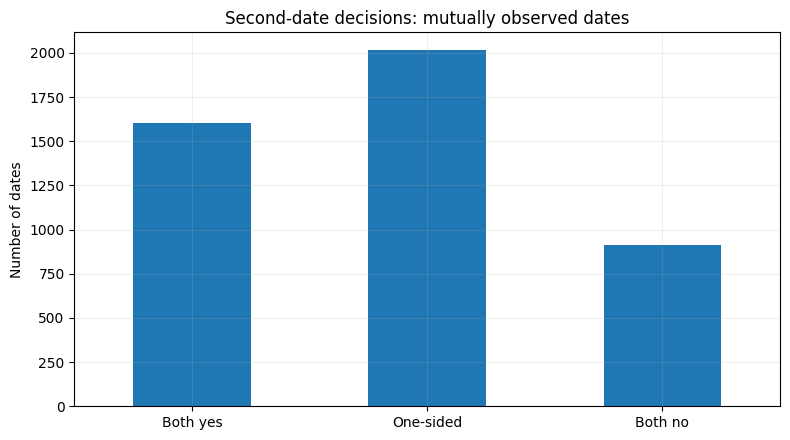

In [10]:
s = ind['SecondDate_YES'].dropna()
valid_pairs = match.dropna(subset=['a_SecondDate_YES','b_SecondDate_YES']).copy()
valid_pairs['outcome_group'] = np.select(
    [(valid_pairs.a_SecondDate_YES.eq(1) & valid_pairs.b_SecondDate_YES.eq(1)),
     (valid_pairs.a_SecondDate_YES.eq(0) & valid_pairs.b_SecondDate_YES.eq(0))],
    ['Both yes','Both no'], default='One-sided')
counts = valid_pairs.outcome_group.value_counts().reindex(['Both yes','One-sided','Both no'],fill_value=0)
print(f'Individual yes: {s.mean():.1%} (n={len(s):,}); missing: {ind.SecondDate_YES.isna().sum():,}')
print(f'Match outcomes available: {len(valid_pairs):,}/{len(match):,}')
display(pd.DataFrame({'dates':counts,'share_of_complete_dates':counts/len(valid_pairs)}))
ax=counts.plot.bar(rot=0, title='Second-date decisions: mutually observed dates')
ax.set(ylabel='Number of dates',xlabel='')
plt.tight_layout();plt.show()

**Output.** Bar chart of both-yes, one-sided, and both-no decisions; individual yes rate is printed separately.

**Inference.** The percentage of individual “yes” responses is **not** the mutual-match rate. The match-level distribution quantifies the difference.

**Decision.** Treat `mutual_second_date` as the principal match-level outcome in later analysis, with missing-pair exclusions explicitly reported.

### Ratings and second-date interest

**Purpose.** Explore how perceived attraction and enjoyment co-vary with an individual second-date decision.

**Method.** Report descriptive statistics, display rating distributions, and compute observed yes rates by rating. Do not interpret post-date ratings as pre-date predictors.

,Attract,Enjoy,Great,OverallRatingNum
count,9071.00,9068.00,9068.00,9068.00
mean,3.08,3.78,2.83,3.93
std,1.27,1.04,1.20,0.90
min,1.00,1.00,1.00,1.00
25%,2.00,3.00,2.00,3.00
50%,3.00,4.00,3.00,4.00
75%,4.00,5.00,4.00,5.00
max,5.00,5.00,5.00,5.00


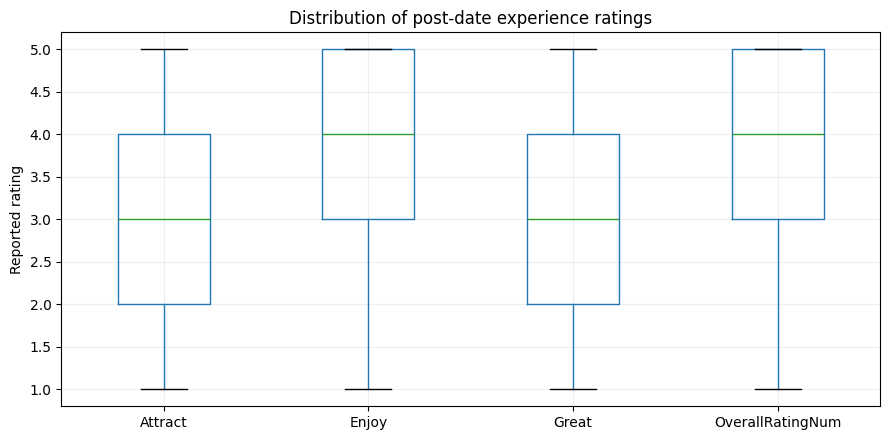

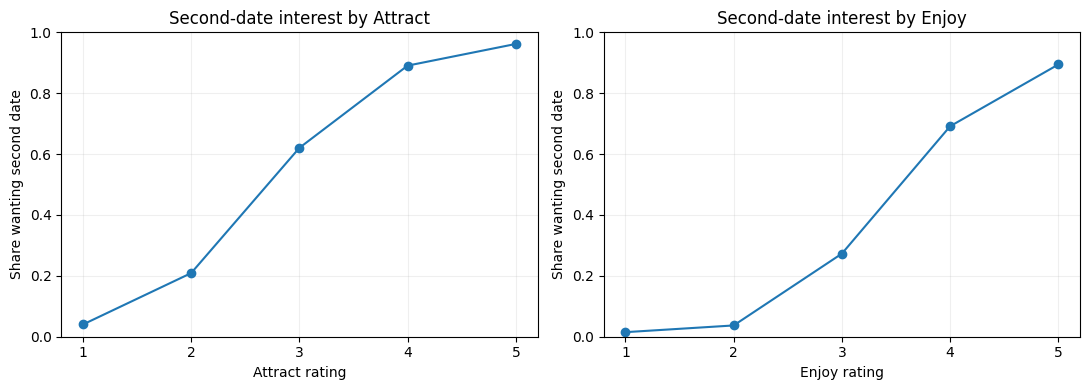

In [11]:
ratings=['Attract','Enjoy','Great','OverallRatingNum']
display(ind[ratings].describe().round(2))
fig,ax=plt.subplots(figsize=(9,4.5))
ind[ratings].boxplot(ax=ax)
ax.set(ylabel='Reported rating',title='Distribution of post-date experience ratings')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))
for a,feature in zip(axes,['Attract','Enjoy']):
    tab=ind.groupby(feature)['SecondDate_YES'].agg(['mean','count'])
    a.plot(tab.index,tab['mean'],marker='o');a.set(xlabel=f'{feature} rating',ylabel='Share wanting second date',ylim=(0,1),title=f'Second-date interest by {feature}')
    a.set_xticks(sorted(tab.index.dropna()))
plt.tight_layout();plt.show()

**Output.** Rating summaries, boxplots, and conditional second-date interest curves.

**Inference.** A rising curve suggests a descriptive association between a post-date rating and second-date interest. This is not proof that increasing the rating would cause a different decision.

**Decision.** Reserve post-date variables for explanatory or post-date prediction models; exclude them from any pre-date model.

### In-person vs virtual date comparisons

**Purpose.** Describe observed outcome differences by reported date format.

**Method.** Use participant-level format labels for individual decisions. Use only consensus match-level format labels for mutual decisions. Exclude “other”, missing, and conflicting formats from the binary format comparison.

,reports,second_date_rate,mean_attraction,mean_enjoyment,mean_duration
date_type_normalized,,,,,
in-person,7499,0.566,3.062,3.797,2.142
zoom,1541,0.621,3.144,3.718,1.041


,mutual_yes_rate,dates
date_type_consensus,,
in-person,0.338,3744
zoom,0.431,756


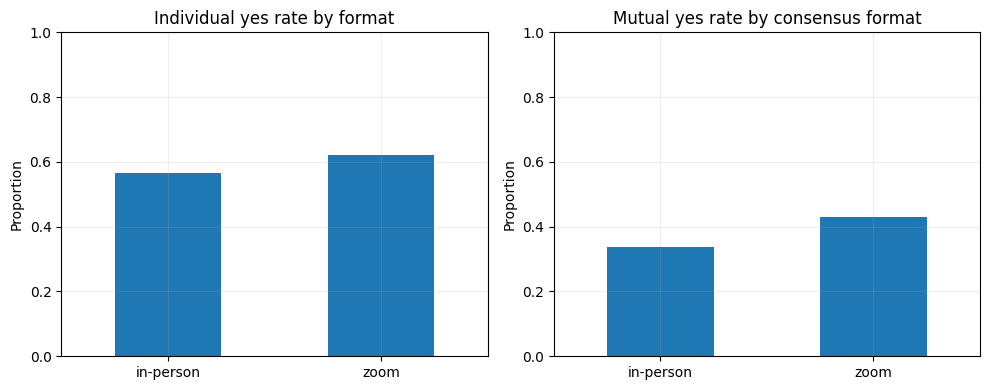

In [12]:
formats=['in-person','zoom']
subset=ind[ind.date_type_normalized.isin(formats)].copy()
by_format=subset.groupby('date_type_normalized').agg(reports=('MatchId','size'),second_date_rate=('SecondDate_YES','mean'),mean_attraction=('Attract','mean'),mean_enjoyment=('Enjoy','mean'),mean_duration=('DateLengthClean','mean'))
display(by_format.round(3))
match_format=match[match.date_type_consensus.isin(formats)].copy()
mutual_by_format=match_format.groupby('date_type_consensus')['mutual_second_date'].agg(['mean','count'])
display(mutual_by_format.rename(columns={'mean':'mutual_yes_rate','count':'dates'}).round(3))
fig,axes=plt.subplots(1,2,figsize=(10,4))
by_format['second_date_rate'].plot.bar(ax=axes[0],rot=0,title='Individual yes rate by format')
mutual_by_format['mean'].plot.bar(ax=axes[1],rot=0,title='Mutual yes rate by consensus format')
for ax in axes: ax.set(ylabel='Proportion',xlabel='',ylim=(0,1))
plt.tight_layout();plt.show()

**Output.** Descriptive table and separate individual- and match-level outcome charts.

**Inference.** Format groups differ in size and may differ in other unmeasured characteristics. These are **unadjusted comparisons**, not causal effects of virtual versus in-person dating.

**Decision.** Later statistical testing should account for pairing, repeated participants, and potential confounders; do not choose a preferred dating format from these raw percentages.

### Partner agreement and disagreement

**Purpose.** Explore whether the two participants experience the same encounter similarly.

**Method.** Plot both partners' attraction ratings, calculate a descriptive correlation, and summarize rating gaps and metadata disagreements. Partner labels A/B are arbitrary.

Attraction rating correlation: -0.055; complete pairs: 4,532
,Absolute rating gap: median 1.0 | mean 1.47
,Date discrepancies: 2134 | Format discrepancies: 28


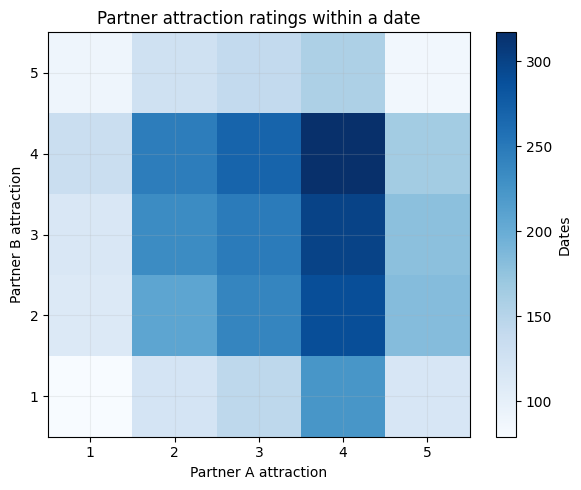

In [13]:
paired=match.dropna(subset=['a_Attract','b_Attract']).copy()
correlation=paired['a_Attract'].corr(paired['b_Attract'])
paired['attraction_gap']=(paired.a_Attract-paired.b_Attract).abs()
print(f'Attraction rating correlation: {correlation:.3f}; complete pairs: {len(paired):,}')
print('Absolute rating gap: median',paired.attraction_gap.median(),'| mean',round(paired.attraction_gap.mean(),2))
print('Date discrepancies:',int(match.date_disagreement.fillna(False).sum()),'| Format discrepancies:',int(match.format_disagreement.fillna(False).sum()))
plt.figure(figsize=(6,5))
plt.hist2d(paired.a_Attract,paired.b_Attract,bins=np.arange(.5,6.5,1),cmap='Blues')
plt.colorbar(label='Dates');plt.xticks(range(1,6));plt.yticks(range(1,6))
plt.xlabel('Partner A attraction');plt.ylabel('Partner B attraction');plt.title('Partner attraction ratings within a date')
plt.tight_layout();plt.show()

**Output.** Paired rating heatmap and descriptive agreement metrics.

**Inference.** Concentration along the diagonal indicates similar ratings; off-diagonal observations indicate mismatched attraction. Correlation alone does not establish agreement or mutual interest.

**Decision.** Preserve both partners' ratings; avoid averaging away asymmetry when building match-level features.

### Optional partner-impression questionnaire coverage

**Purpose.** Determine whether the `PI1`–`PI14` attributes can support a generalizable analysis.

**Method.** Calculate response coverage per attribute and compare questionnaire completion by date format and second-date decision.

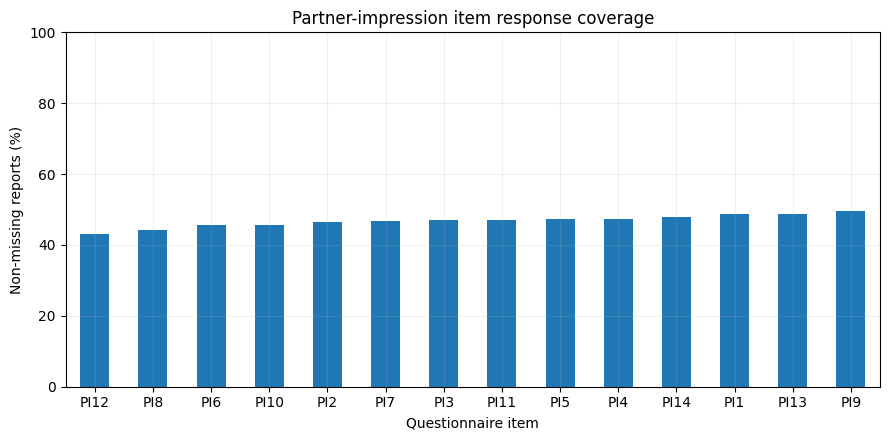

At least one PI response: 54.1 %


,mean,count
date_type_normalized,,
in-person,0.552,7499
other,0.429,28
zoom,0.491,1541


,mean,count
SecondDate_YES,,
0.0,0.514,3850
1.0,0.562,5221


In [14]:
pi=[f'PI{i}' for i in range(1,15)]
coverage=ind[pi].notna().mean().sort_values()
fig,ax=plt.subplots(figsize=(9,4.5))
coverage.mul(100).plot.bar(ax=ax,rot=0)
ax.set(title='Partner-impression item response coverage',ylabel='Non-missing reports (%)',xlabel='Questionnaire item',ylim=(0,100))
plt.tight_layout();plt.show()
print('At least one PI response:',round(ind.pi_any_answered.mean()*100,1),'%')
display(ind.groupby('date_type_normalized')['pi_any_answered'].agg(['mean','count']).round(3))
display(ind.groupby('SecondDate_YES')['pi_any_answered'].agg(['mean','count']).round(3))

**Output.** Per-item completion chart and completion rates by observed groups.

**Inference.** If response propensity differs by format or outcome, complete-case analyses of partner traits may be selection-biased. Even equal observed rates would not prove missingness is random.

**Decision.** Analyze optional PI variables in a separately labeled subset, report its size, and avoid indiscriminate mean imputation.

### Duration patterns and quality flags

**Purpose.** Examine date length without allowing extreme self-reported durations to dominate visualization.

**Method.** Report duration quantiles and display durations up to six hours, while retaining and counting the flagged longer values.

Duration quantiles (hours):


,hours
0.00,0.17
0.25,1.50
0.50,2.00
0.75,2.50
0.90,3.00
0.95,3.50
0.99,5.00
1.00,15.00


Over 6 hours: 31 | Missing: 109


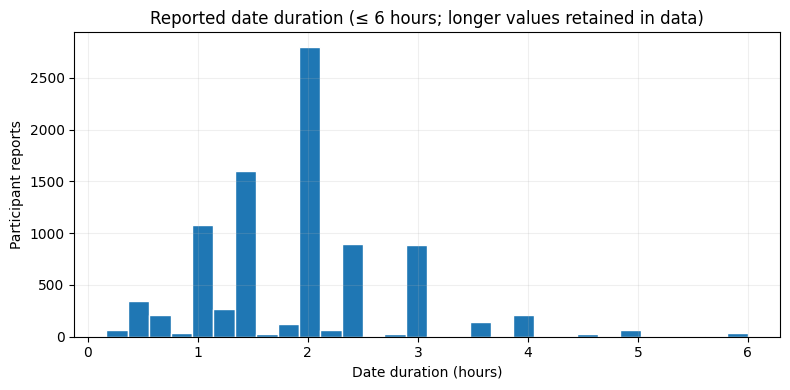

In [15]:
duration=ind.DateLengthClean.dropna()
print('Duration quantiles (hours):')
display(duration.quantile([0,.25,.5,.75,.9,.95,.99,1]).rename('hours').to_frame())
print('Over 6 hours:',int((duration>6).sum()),'| Missing:',int(ind.DateLengthClean.isna().sum()))
plt.figure(figsize=(8,4))
plt.hist(duration[duration<=6],bins=30,edgecolor='white')
plt.xlabel('Date duration (hours)');plt.ylabel('Participant reports');plt.title('Reported date duration (≤ 6 hours; longer values retained in data)')
plt.tight_layout();plt.show()

**Output.** Duration percentiles and a visualization with an explicitly limited x-axis sample.

**Inference.** Self-reported durations may differ between partners and contain extreme but potentially legitimate values.

**Decision.** Preserve duration flags and both reports. Any winsorization or exclusion belongs in a documented sensitivity analysis, not silent preprocessing.

### EDA summary and next-stage decisions

**Purpose.** Record key findings reproducibly rather than relying on manually copied numbers.

**Method.** Compute compact aggregate summaries in memory and print an evidence-based summary. This stage does not conduct hypothesis tests.

In [16]:
print(f'Observed individual second-date yes rate: {s.mean():.1%}')
print(f'Observed mutual second-date yes rate: {valid_pairs.outcome_group.eq("Both yes").mean():.1%} (complete dates only)')
print(f'Partner attraction correlation: {correlation:.3f}')
print(f'Optional PI coverage: {coverage.min():.1%}–{coverage.max():.1%}')
print('EDA summary computed in notebook memory.')


Observed individual second-date yes rate: 57.6%
,Observed mutual second-date yes rate: 35.3% (complete dates only)
,Partner attraction correlation: -0.055
,Optional PI coverage: 43.1%–49.5%
,EDA summary computed in notebook memory.


### conclusions

**Established:** Descriptive distributions, paired outcome categories, format comparisons, partner-rating agreement, optional-questionnaire coverage, and duration quality patterns.

**Not established:** Causal mechanisms, statistically significant differences, generalization beyond the sample, or prospective prediction performance.

**Milestone 4 — Statistical inference plan:**
- Test associations of attraction/enjoyment with second-date interest using methods that account for clustered participants.
- Estimate format differences with uncertainty intervals and appropriate adjustments; report observational limitations.
- Quantify partner agreement beyond correlation.
- Assess whether PI-questionnaire completion is associated with observed covariates.

**Reproducibility:** The notebook uses Milestone 2 CSVs without overwriting them; only aggregate EDA tables are exported.

### Summary

**What problem were we solving?**  
What do individual reports and paired dates reveal before fitting models?

**What did we find?**  
Second-date intention varies with subjective ratings, and partners do not always agree; supplemental questionnaire completion is uneven.

**What did we build or do?**  
We plotted outcomes, ratings, formats, paired agreement, duration and coverage.

**Why did we do it this way?**  
These checks identify misleading comparisons and guide safe feature selection.

**What should we do next?**  
Use participant-disjoint model validation and report paired outcomes separately from individual intentions.

## Stage 3 — Methodology and Baseline Development

**Purpose.** Translate exploratory observations into testable associations and an explicit supervised evaluation contract before selecting advanced models.

**Primary model-selection metric:** training-side grouped cross-validated **log loss**, capturing probability quality; ROC-AUC and PR-AUC are complementary ranking metrics. Also report Brier score, balanced accuracy, per-class precision/recall/F1 and errors.

**Acceptance policy:** outperform the dummy prevalence baseline on grouped CV and show no participant overlap; there is **no evidence-backed numerical deployment acceptance threshold**, so this is exploratory research, not a launch-approved model.

**Errors and threshold:** default probability threshold 0.50 is frozen before final testing for diagnostic comparability, **not** cost-optimized. False positives falsely imply reciprocal interest; false negatives overlook potential interest. Costs depend on intended use and no defensible business cost matrix is available. Do not adjust thresholds on the holdout.

**Validation:** build a graph of participant–date connections and split entire connected components. Five-fold group CV uses only the development partition. Imputation and feature transformation fit inside model pipelines on each fold.

**Computational constraints:** run a bounded model grid with reproducible seeds; native EBM and crossed-participant mixed-effects analysis remain future experiments.

### Statistical Hypotheses and Research Boundaries

### Setup and reproducibility
**Purpose:** Load the actual cleaned datasets, verify key columns, and make calculations reproducible.  
**Method:** Use NumPy, pandas, SciPy, statsmodels, and Matplotlib. Set a fixed random seed. No source data are modified.

In [17]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
RNG = np.random.default_rng(42)
# M2 tables are already in memory: ind and match
assert len(ind)==9084 and len(match)==4542
assert ind.groupby('MatchId').size().eq(2).all()
print('Individual reports:',len(ind),'| Unique dates:',len(match),'| Unique people:',ind.user_id.nunique())
print('Required fields present:', {'SecondDate_YES','Attract','Enjoy','MatchId'}.issubset(ind.columns))
results=[]
def record(test,n,effect,ci,p,notes):
    results.append(dict(test=test,n=n,effect=effect,ci=ci,p_value=p,notes=notes))

Individual reports: 9084 | Unique dates: 4542 | Unique people: 6262
,Required fields present: True


### Hypotheses, outcome definitions, and analysis units
**Purpose:** Avoid choosing hypotheses after seeing a convenient p-value.

| ID | Null hypothesis | Alternative | Unit | Primary test |
|---|---|---|---|---|
| H1 | Mutual second-date rate is equal for in-person and virtual dates | Rates differ | Date (match) | Two-proportion z test / permutation |
| H2 | Post-date attraction is unrelated to a participant's second-date decision | Positive association | Individual response, clustered by date | Cluster-bootstrap difference in mean ratings |
| H3 | Partners' attraction ratings are unrelated | Correlation differs from zero | Date | Spearman correlation + permutation |
| H4 | Date duration is unrelated to mutual second-date interest | Association differs from zero | Date | Spearman correlation + permutation |

**Preprocessing choices:** H1 excludes dates with unknown or conflicting format and missing mutual-interest outcome. H4 uses average self-reported duration only when both are observed, excludes durations >6 h as a sensitivity rule, and does not infer a causal effect. For H2 we resample whole matches so paired responses stay together. All tests are two-sided; 95% CIs where reported. A familywise correction across the four headline tests is applied after analysis.

### H1 — Does date format relate to mutual interest?
**Purpose:** Test whether virtual and in-person dates differ in the proportion where **both** partners want another date.  
**Method:** Use match-level consensus date type; calculate difference in proportions (virtual − in-person), 95% bootstrap CI, and a two-sided permutation p-value. No causal claim: assignment to date format may be confounded.

In [18]:
d1=match.loc[match.date_type_consensus.isin(['zoom','in-person']) & match.mutual_second_date.notna(), ['date_type_consensus','mutual_second_date']].copy()
print(d1.groupby('date_type_consensus').mutual_second_date.agg(['size','mean']))
v=d1.loc[d1.date_type_consensus=='zoom','mutual_second_date'].to_numpy()
i=d1.loc[d1.date_type_consensus=='in-person','mutual_second_date'].to_numpy()
obs=v.mean()-i.mean()
boot=np.array([RNG.choice(v,len(v),True).mean()-RNG.choice(i,len(i),True).mean() for _ in range(3000)])
ci=np.quantile(boot,[.025,.975]); pooled=np.r_[v,i]; n_v=len(v)
perm=np.array([ (lambda z:z[:n_v].mean()-z[n_v:].mean())(RNG.permutation(pooled)) for _ in range(3000)])
p=(1+(abs(perm)>=abs(obs)).sum())/(len(perm)+1)
record('H1: format vs mutual interest',len(d1),float(obs),str(np.round(ci,4)),float(p),'Difference virtual minus in-person; match-level')
print(f'Virtual − in-person mutual-interest rate: {obs:+.3%}; 95% bootstrap CI [{ci[0]:+.3%}, {ci[1]:+.3%}]; permutation p={p:.4g}')
display(Markdown(f'**Inference:** The observed difference is **{obs:+.1%}** (virtual minus in-person), with a 95% bootstrap interval **[{ci[0]:+.1%}, {ci[1]:+.1%}]** and permutation p = **{p:.4f}**. This is an association, not proof that date format changes attraction. **Decision:** Report both group rates and uncertainty; consider confounders before interpretation.'))

                     size      mean
,date_type_consensus                
,in-person            3744  0.337874
,zoom                  756  0.431217


Virtual − in-person mutual-interest rate: +9.334%; 95% bootstrap CI [+5.591%, +13.155%]; permutation p=0.0003332


**Inference:** The observed difference is **+9.3%** (virtual minus in-person), with a 95% bootstrap interval **[+5.6%, +13.2%]** and permutation p = **0.0003**. This is an association, not proof that date format changes attraction. **Decision:** Report both group rates and uncertainty; consider confounders before interpretation.

### H2 — Is perceived attraction associated with wanting a second date?
**Purpose:** Quantify the relationship between attraction reported *after* the date and second-date interest.  
**Method:** Compare mean attraction ratings between Yes/No responses; bootstrap whole dates (clusters), not individual rows, to respect paired observations. This is explanatory, **not a pre-date prediction model**.

In [19]:
d2=ind[['MatchId','Attract','SecondDate_YES']].dropna().copy()
d2=d2[d2.SecondDate_YES.isin([0,1])]
yes=d2.loc[d2.SecondDate_YES==1,'Attract'].mean(); no=d2.loc[d2.SecondDate_YES==0,'Attract'].mean(); obs2=yes-no
# Aggregate cluster sufficient statistics for efficient cluster bootstrap
agg=d2.assign(y_sum=np.where(d2.SecondDate_YES==1,d2.Attract,0), n_sum=np.where(d2.SecondDate_YES==0,d2.Attract,0), y_n=(d2.SecondDate_YES==1).astype(int), n_n=(d2.SecondDate_YES==0).astype(int)).groupby('MatchId')[['y_sum','n_sum','y_n','n_n']].sum().to_numpy()
bs=[]
for _ in range(3000):
    a=agg[RNG.integers(0,len(agg),len(agg))].sum(axis=0)
    bs.append(a[0]/a[2]-a[1]/a[3])
ci2=np.quantile(bs,[.025,.975]); p2=2*min((np.array(bs)<=0).mean(),(np.array(bs)>=0).mean());p2=max(1/3001,p2)
record('H2: attraction vs second-date decision',len(d2),float(obs2),str(np.round(ci2,4)),float(p2),'Cluster bootstrap by MatchId; approximate bootstrap tail p')
print(f'Mean attraction: Yes={yes:.3f}, No={no:.3f}; difference={obs2:.3f}; 95% cluster bootstrap CI={np.round(ci2,3)}; approximate bootstrap tail p={p2:.4g}')
display(Markdown(f'**Inference:** People who wanted another date rated attraction **{obs2:.2f} points higher** on average (1–5 scale); 95% date-cluster bootstrap CI **[{ci2[0]:.2f}, {ci2[1]:.2f}]**. **Decision:** Retain attraction as a post-date explanatory feature only. The bootstrap-tail p-value is approximate; prioritize the confidence interval.'))

Mean attraction: Yes=3.808, No=2.083; difference=1.726; 95% cluster bootstrap CI=[1.688 1.766]; approximate bootstrap tail p=0.0003332


**Inference:** People who wanted another date rated attraction **1.73 points higher** on average (1–5 scale); 95% date-cluster bootstrap CI **[1.69, 1.77]**. **Decision:** Retain attraction as a post-date explanatory feature only. The bootstrap-tail p-value is approximate; prioritize the confidence interval.

### H3 — Do two partners agree about attraction?
**Purpose:** Quantify agreement/association in two partners’ independent attraction ratings.  
**Method:** One observation per date; Spearman rank correlation with a permutation null (shuffle one partner's rating across dates). This measures association, not absolute agreement.

In [20]:
d3=match[['a_Attract','b_Attract']].dropna()
a=d3.a_Attract.to_numpy(); bb=d3.b_Attract.to_numpy(); rho=stats.spearmanr(a,bb).statistic
p3arr=np.array([stats.spearmanr(a,RNG.permutation(bb)).statistic for _ in range(2000)])
p3=(1+(np.abs(p3arr)>=abs(rho)).sum())/(len(p3arr)+1)
record('H3: partner attraction association',len(d3),float(rho),'not estimated',float(p3),'Spearman correlation; match-level permutation')
print(f'n={len(d3)}; Spearman rho={rho:.3f}; permutation p={p3:.4g}')
display(Markdown(f'**Inference:** Partners’ attraction ratings have Spearman ρ = **{rho:.3f}** (n={len(d3)}, permutation p={p3:.4f}). **Decision:** Describe strength/direction, and avoid interpreting correlation as exact rating agreement.'))

n=4532; Spearman rho=-0.055; permutation p=0.0004998


**Inference:** Partners’ attraction ratings have Spearman ρ = **-0.055** (n=4532, permutation p=0.0005). **Decision:** Describe strength/direction, and avoid interpreting correlation as exact rating agreement.

### H4 — Is date duration associated with mutual interest?
**Purpose:** Explore whether longer dates tend to be associated with mutual second-date interest.  
**Method:** Match-level Spearman correlation using both-reported durations. Exclude average durations >6 hours for the primary sensitivity rule; compare with all observed durations. Self-reported duration may reflect the date outcome rather than predict it.

In [21]:
d4=match.loc[match.duration_both_observed.eq(True),['duration_mean_hours','mutual_second_date']].dropna()
d4=d4[d4.duration_mean_hours>0]
trim=d4[d4.duration_mean_hours<=6]
r4=stats.spearmanr(trim.duration_mean_hours,trim.mutual_second_date).statistic
allr=stats.spearmanr(d4.duration_mean_hours,d4.mutual_second_date).statistic
p4arr=np.array([stats.spearmanr(trim.duration_mean_hours.to_numpy(),RNG.permutation(trim.mutual_second_date.to_numpy())).statistic for _ in range(2000)])
p4=(1+(np.abs(p4arr)>=abs(r4)).sum())/(len(p4arr)+1)
record('H4: duration vs mutual interest',len(trim),float(r4),'not estimated',float(p4),'Spearman correlation; >6h sensitivity exclusion')
print(f'<=6h: n={len(trim)}, rho={r4:.3f}, permutation p={p4:.4g}; all durations: n={len(d4)}, rho={allr:.3f}')
display(Markdown(f'**Inference:** For dates ≤6 h, duration and mutual interest have Spearman ρ = **{r4:.3f}** (permutation p={p4:.4f}). Including all valid durations gives ρ = **{allr:.3f}**. **Decision:** Treat as a descriptive association, not a recommendation to prolong dates.'))

<=6h: n=4426, rho=0.238, permutation p=0.0004998; all durations: n=4443, rho=0.242


**Inference:** For dates ≤6 h, duration and mutual interest have Spearman ρ = **0.238** (permutation p=0.0005). Including all valid durations gives ρ = **0.242**. **Decision:** Treat as a descriptive association, not a recommendation to prolong dates.

### Multiplicity control and consolidated evidence
**Purpose:** Avoid interpreting four exploratory p-values as four independent confirmatory discoveries.  
**Method:** Holm-adjust the four headline p-values. Report effect size and uncertainty alongside adjusted p-values. H2's p-value is an approximate bootstrap-tail estimate, so its adjusted value is exploratory.

,test,n,effect,ci,p_value,notes,p_holm,holm_significant_0_05
0,H1: format vs mutual interest,4500,0.093343,[0.0559 0.1316],0.000333,Difference virtual minus in-person; match-level,0.001333,True
1,H2: attraction vs second-date decision,9071,1.725677,[1.6881 1.7664],0.000333,Cluster bootstrap by MatchId; approximate boot...,0.001333,True
2,H3: partner attraction association,4532,-0.055416,not estimated,0.000500,Spearman correlation; match-level permutation,0.001333,True
3,H4: duration vs mutual interest,4426,0.237986,not estimated,0.000500,Spearman correlation; >6h sensitivity exclusion,0.001333,True


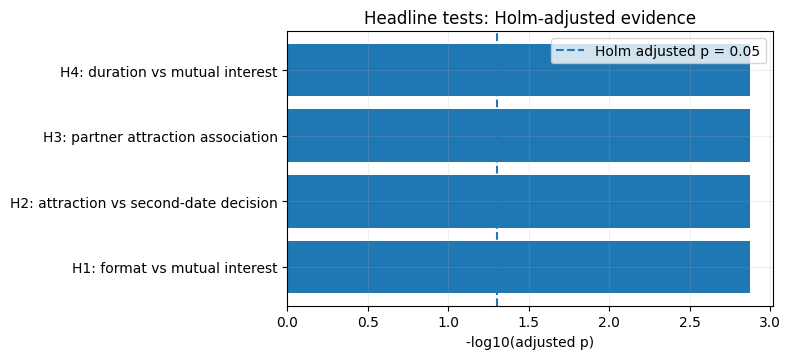

Hypothesis summary retained in notebook memory.


In [22]:
summary=pd.DataFrame(results)
summary['p_holm']=multipletests(summary.p_value,method='holm')[1]
summary['holm_significant_0_05']=summary.p_holm<.05
display(summary)
fig,ax=plt.subplots(figsize=(8,3.7))
ax.barh(summary.test, -np.log10(summary.p_holm.clip(lower=1e-6)))
ax.axvline(-np.log10(.05),linestyle='--',label='Holm adjusted p = 0.05')
ax.set_xlabel('-log10(adjusted p)');ax.set_title('Headline tests: Holm-adjusted evidence');ax.legend();plt.tight_layout();plt.show()
# The hypothesis table is retained as `summary` in memory.
print('Hypothesis summary retained in notebook memory.')

### Bias, interpretation, and decision log
**Purpose:** Keep the results defensible when presenting them in a portfolio or research report.

**Key limitations**
- Participants can appear in multiple dates. Match-level permutation and date-cluster bootstrap protect against two reports from the *same* date being treated as independent, **but do not fully handle repeated participants across different dates**. Consequently, p-values for H1/H3/H4 may be optimistic. A participant-network-aware robustness analysis is needed before confirmatory claims.
- Virtual versus in-person dates were not necessarily randomly assigned. Selection, age, location, and other factors may confound associations.
- Post-date ratings are measured alongside outcomes; do not use them for pre-date prediction.
- The 14 PI ratings are optional and have substantial missingness. They are not included in headline tests.
- P-values are sensitive to sample size. Practical importance should be judged from effect size, interval width, and domain context.

**Decision:** Use these results to guide model design, not to declare causal determinants of attraction. Milestone 5 should compare post-date classification against a simple baseline, avoid target leakage, and evaluate participant-overlap explicitly.

### Statistical Testing Handoff
**Deliverable:** This executed notebook, including the in-memory `summary` hypothesis table.

**Next milestone:** Machine Learning and Explainability. Define time-of-prediction feature availability, establish a majority-class baseline, keep both partners' records in the same split, and assess repeated-person leakage. Explain predictions as statistical associations, not behavioral laws.

### Participant-Network-Disjoint Experimental Design

### Research tasks and estimands

**Purpose.** Avoid mixing distinct questions.

| Task | Unit | Target | Permitted inputs | Interpretation |
|---|---|---|---|---|
| Individual post-date interest | Participant report | `SecondDate_YES` | Ratings actually available before decision is made (timing must be verified) | Classify expressed interest after date |
| Mutual post-date interest | Date pair | `mutual_second_date` | Both partners’ ratings only if legitimately available at prediction time | Classify mutual interest after date |
| Pre-date compatibility | Date pair | `mutual_second_date` | Strictly pre-date information only | **Not yet supported** by verified features |

**Inference.** The present models are explanatory/post-date classifiers, not pre-date kiss or compatibility predictors. **Decision.** No pre-date claims without a separately verified feature set.

### Evaluation matrix (frozen proposal)

**Method.** Separate *ranking*, *probability quality*, *classification decisions*, and *generalization*.

| Layer | Individual | Mutual | Primary report |
|---|---|---|---|
| Dummy baseline | Yes | Yes | Prevalence, log loss, Brier |
| Logistic baseline | Yes | Yes | ROC-AUC, log loss |
| Match-disjoint holdout | Yes | Yes | Performance on unseen dates (may reuse participants) |
| Component-disjoint holdout | Yes | Yes | Performance on unseen participants |
| Grouped CV within development | Yes | Yes | Mean, SD, fold-level metrics |
| Calibration | Yes | Yes | Brier, log loss, calibration curve |
| Threshold metrics | Yes | Yes | Precision, recall, F1, balanced accuracy |
| Uncertainty | Yes | Yes | Component-cluster bootstrap intervals |

**Primary selection:** cross-validated ROC-AUC subject to acceptable log loss and calibration; report PR-AUC and prevalence. For mutually rare outcomes, also evaluate PR-AUC prominently. Thresholds are chosen on development folds only. **Final holdout is evaluated once.**

### Feature and leakage policy

**Purpose.** Prevent outcome proxies and participant identity from inflating scores.

- **Never predictors:** `MatchId`, `user_id`, `partner_id`, `a_user_id`, `b_user_id`, `component_id`, `SecondDate`, `SecondDate_YES`, `a_SecondDate_YES`, `b_SecondDate_YES`, `mutual_second_date`, `one_sided_interest`.
- **Conditional post-date predictors:** `Attract`, `Enjoy`, `Great`, `OverallRatingNum`, attachment-style ratings, `PI1`–`PI14`; verify questionnaire ordering and measurement timing.
- **Date type/duration:** duration is observed after the date; format disagreements must be flagged; do not claim pre-date availability of actual duration.
- **Derived flags:** exclude any flag derived from labels, post-outcome measurements, or the entire dataset unless fit within the training fold.
- **Processing:** imputation, encoding, scaling, feature selection, calibration and tuning must fit on development folds only.

**Decision.** baseline validation must audit each column and timestamp before an allowlist is frozen.

### Load the prepared data

**Method.** Reuse the two cleaned tables created in M2 in memory; check primary keys and reciprocal identities.

In [23]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
individual = df.copy(deep=True)
matches = match.copy(deep=True)
assert matches.MatchId.is_unique
assert individual.groupby('MatchId').size().eq(2).all()
assert (matches.a_user_id == matches.b_partner_id).all()
assert (matches.b_user_id == matches.a_partner_id).all()
print('Individual reports:', len(individual), '| Matches:', len(matches))

Individual reports: 9084 | Matches: 4542


**Inference.** Each match contributes two reports; the two reports must not be split independently. **Decision.** The match table is the atomic unit for pair-level partitioning.

### Build participant graph

**Purpose.** A match-disjoint split can still reuse people. **Method.** Create an undirected graph: participant = node, date = edge. Connected components are indivisible split groups.

In [24]:
parent = {}
def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]
def union(a, b):
    a, b = find(a), find(b)
    if a != b:
        parent[b] = a
for a, b in zip(matches.a_user_id, matches.b_user_id):
    union(int(a), int(b))
matches['component_id'] = [find(int(a)) for a in matches.a_user_id]
component_sizes = matches.groupby('component_id').size()
unique_participants = set(matches.a_user_id) | set(matches.b_user_id)
print('Participants:', len(unique_participants))
print('Components:', component_sizes.size)
print('Largest component, dates:', component_sizes.max())

Participants: 6262
,Components: 1726
,Largest component, dates: 199


**Inference.** A connected component must remain entirely in either train or test. **Decision.** Use `component_id` as the strict generalization group; never use it as a predictive feature.

### Construct a participant-disjoint holdout

**Method.** Split by graph component using a fixed seed. Verify *both endpoints* of every edge and every match ID. The 20% target applies approximately to components, not necessarily to dates or participants.

In [25]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(matches, groups=matches.component_id))
train, test = matches.iloc[train_idx].copy(), matches.iloc[test_idx].copy()
train_people = set(train.a_user_id) | set(train.b_user_id)
test_people = set(test.a_user_id) | set(test.b_user_id)
assert not (train_people & test_people), 'PARTICIPANT LEAKAGE'
assert not (set(train.MatchId) & set(test.MatchId)), 'MATCH LEAKAGE'
assert not (set(train.component_id) & set(test.component_id)), 'COMPONENT LEAKAGE'
print('PASS: no participant, match, or component overlap')
print('Train dates:', len(train), '| Test dates:', len(test))

PASS: no participant, match, or component overlap
,Train dates: 3551 | Test dates: 991


### Quantify split representativeness

**Purpose.** Zero overlap alone does not ensure fair evaluation. **Method.** Inspect target prevalence, missing targets, date format, sample size, and participant counts in each partition.

In [26]:
def describe_partition(label, frame):
    y = frame['mutual_second_date']
    return {'partition': label, 'dates': len(frame),
            'participants': len(set(frame.a_user_id) | set(frame.b_user_id)),
            'positive_mutual': int(y.eq(1).sum()),
            'negative_mutual': int(y.eq(0).sum()),
            'unknown_mutual': int(y.isna().sum()),
            'positive_rate_known': round(y.mean(), 4),
            'in_person_fraction': round(frame.date_type_consensus.eq('in-person').mean(), 4),
            'virtual_fraction': round(frame.date_type_consensus.eq('zoom').mean(), 4)}
summary = pd.DataFrame([describe_partition('train', train), describe_partition('test', test)])
display(summary)
print('Absolute positive-rate gap:', round(abs(summary.loc[0, 'positive_rate_known'] - summary.loc[1, 'positive_rate_known']), 4))

,partition,dates,participants,positive_mutual,negative_mutual,unknown_mutual,positive_rate_known,in_person_fraction,virtual_fraction
0,train,3551,4927,1255,2289,7,0.3541,0.8246,0.1673
1,test,991,1335,346,642,3,0.3502,0.8234,0.1635


Absolute positive-rate gap: 0.0039


**Inference.** If outcome prevalence, format mix, or sample sizes diverge substantially, evaluate multiple candidate seeds **using only covariates and target balance criteria fixed in advance**, then lock a single holdout before fitting any model. Never choose a seed based on model test scores.

**Decision.** Treat this split as a *candidate*, not automatically the final frozen holdout.

### Development-only cross-validation

**Method.** Build folds solely inside the development partition, grouped by participant component. Use identical fold indices for all candidate models. Do not use the test partition for hyperparameter tuning.

In [27]:
cv = GroupKFold(n_splits=5)
for k, (a, b) in enumerate(cv.split(train, groups=train.component_id), 1):
    fold_train = train.iloc[a]
    fold_val = train.iloc[b]
    p_train = set(fold_train.a_user_id) | set(fold_train.b_user_id)
    p_val = set(fold_val.a_user_id) | set(fold_val.b_user_id)
    assert not (p_train & p_val)
    print(f'Fold {k}: {len(a)} train dates, {len(b)} validation dates, overlap=0')

Fold 1: 2840 train dates, 711 validation dates, overlap=0
,Fold 2: 2841 train dates, 710 validation dates, overlap=0
,Fold 3: 2841 train dates, 710 validation dates, overlap=0
,Fold 4: 2841 train dates, 710 validation dates, overlap=0
,Fold 5: 2841 train dates, 710 validation dates, overlap=0


**Decision.** In baseline validation, also check fold-level class counts and date-format distributions; use stratified-group methods only if they preserve component separation and do not cause unstable folds.

### Reporting and uncertainty contract

- Report ROC-AUC, PR-AUC (with positive prevalence), log loss, Brier score, balanced accuracy, precision, recall, F1, and confusion matrices.
- Fit any calibration model on training/validation data only, not the final test set.
- Use component-level cluster bootstrap for test confidence intervals where feasible; resample **components**, not individual rows.
- Report both match-disjoint and participant-disjoint results; label their generalization claims distinctly.
- Inspect performance by date format and questionnaire completion; avoid overclaiming on small groups.
- Never interpret predictive importance as causal effects.

**Inference.** The strongest model is not automatically the one with the largest single-run ROC-AUC. **Decision.** Prioritize repeatability, probability quality, and out-of-participant generalization.

### Freeze participant-disjoint validation in memory

**Method:** Create the same component-aware assignment deterministically from the original source and fixed random state. Keep the assignment and split diagnostics in memory. All later supervised experiments use these assignments.


In [28]:
assignments = matches[['MatchId', 'component_id']].copy()
assignments['partition'] = np.where(matches.index.isin(test_idx), 'test', 'train')
assert assignments.MatchId.is_unique
print('Frozen participant-disjoint assignment recreated in memory:')
display(assignments.partition.value_counts().to_frame('dates'))
display(summary)


Frozen participant-disjoint assignment recreated in memory:


,dates
partition,
train,3551
test,991


,partition,dates,participants,positive_mutual,negative_mutual,unknown_mutual,positive_rate_known,in_person_fraction,virtual_fraction
0,train,3551,4927,1255,2289,7,0.3541,0.8246,0.1673
1,test,991,1335,346,642,3,0.3502,0.8234,0.1635


### Validation Design Conclusions

**Findings:** The participant graph supplies a principled mechanism for strict train/test separation; assertions verify zero overlap. Split quality still requires inspection, and feature timing remains unresolved.

**Limitations:** A single graph-component holdout is one sampling realization; component sizes differ, and partner network structure may correlate with outcomes. Prior machine learning performance figures are not validated under this new protocol.

**baseline validation checklist:** audit identity consistency, quantify overlap under previous machine learning splits, inspect graph and fold distributions, create a feature timing allowlist, rebuild baselines with leakage-safe pipelines, and freeze a defensible holdout.

**Gate:** Do not begin CatBoost/EBM tuning until baseline validation passes.

### Frozen Predictors, Leakage Audit and Baseline Comparison

### Load and verify frozen participant-network validation assignments
**Purpose:** Reproduce the split exactly, rather than creating a new favorable split.  
**Method:** Join participant-network validation assignments by `MatchId`; verify uniqueness and full coverage.  
**Decision rule:** Stop if any match is missing or assigned twice.

In [29]:
from pathlib import Path
import numpy as np, pandas as pd
from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss, balanced_accuracy_score
from scipy.stats import chi2_contingency
from sklearn.base import clone
individual=df.copy(deep=True)
match=match.copy(deep=True)
assign=assignments.copy(deep=True)
assert assign.MatchId.is_unique and match.MatchId.is_unique
assert set(match.MatchId)==set(assign.MatchId)
m=match.merge(assign,on='MatchId',validate='one_to_one')
assert set(m.partition)=={'train','test'}
print('Matches:',len(m),'Train:',(m.partition=='train').sum(),'Sealed test:',(m.partition=='test').sum())

Matches: 4542 Train: 3551 Sealed test: 991


**Inference:** The printed counts should reproduce participant-network validation. **Decision:** Freeze the test assignments and do not select features, thresholds, or models using test outcomes.

### Participant identity, graph, and overlap audit
**Purpose:** Detect leakage through either member of a dating pair.  
**Method:** Check reciprocal identities, repeated participants, cross-partition intersections, and component integrity.  
**Decision rule:** Any cross-partition participant or component overlap invalidates the holdout.

In [30]:
assert (m.a_user_id==m.b_partner_id).all() and (m.b_user_id==m.a_partner_id).all()
assert (m.a_user_id!=m.b_user_id).all()
assert individual.groupby('MatchId').size().eq(2).all()
tr=m[m.partition=='train'].copy(); te=m[m.partition=='test'].copy()
people=lambda d:set(d.a_user_id)|set(d.b_user_id)
train_people,test_people=people(tr),people(te)
intersection=train_people & test_people
assert len(intersection)==0
assert not(set(tr.MatchId)&set(te.MatchId))
assert not(set(tr.component_id)&set(te.component_id))
counts=pd.concat([m.a_user_id,m.b_user_id]).value_counts()
print('Participant overlap:',len(intersection),'Repeated participants:',int((counts>1).sum()),'Max dates:',int(counts.max()))
print('Train participants:',len(train_people),'Test participants:',len(test_people),'Components:',m.component_id.nunique())

Participant overlap: 0 Repeated participants: 1976 Max dates: 7


Train participants: 4927 Test participants: 1335 Components: 1726


**Inference:** A zero intersection means the held-out partition tests people unseen during training. **Decision:** Use connected components, not individual rows or matches, as the grouping unit.

### Feature timing and leakage policy
**Purpose:** Avoid target-derived, identity, and post-outcome features.  
**Method:** Create explicit allowlists for **post-date explanatory** models; never include `SecondDate`, IDs, or features constructed from decisions. Ratings may be contemporaneous with the decision, so these are *not pre-date predictions*.  
**Decision rule:** Reject any unapproved input.

In [31]:
INDIV_FEATURES=['Enjoy','Attract','Great','PSAnx','PSAvoid','SafeHav','SecBase','DateLengthClean','DateType']
MUTUAL_FEATURES=['a_Enjoy','b_Enjoy','a_Attract','b_Attract','a_Great','b_Great','duration_mean_hours','date_type_consensus']
forbidden={'SecondDate','SecondDate_YES','mutual_second_date','one_sided_interest','MatchId','user_id','partner_id','a_user_id','b_user_id','component_id','partition'}
assert not (set(INDIV_FEATURES)|set(MUTUAL_FEATURES))&forbidden
assert set(INDIV_FEATURES).issubset(individual.columns)
assert set(MUTUAL_FEATURES).issubset(m.columns)
print('Individual allowlist:',INDIV_FEATURES)
print('Mutual allowlist:',MUTUAL_FEATURES)
print('Caution: DateType and consensus date format are observational, not randomized treatments.')

Individual allowlist: ['Enjoy', 'Attract', 'Great', 'PSAnx', 'PSAvoid', 'SafeHav', 'SecBase', 'DateLengthClean', 'DateType']
,Mutual allowlist: ['a_Enjoy', 'b_Enjoy', 'a_Attract', 'b_Attract', 'a_Great', 'b_Great', 'duration_mean_hours', 'date_type_consensus']
,Caution: DateType and consensus date format are observational, not randomized treatments.


**Inference:** Feature allowlisting blocks direct target leakage, but cannot prove questionnaire timing. **Decision:** Interpret model performance as post-date decision reconstruction until collection order is established.

### Train-only distribution and missingness checks
**Purpose:** Identify train/holdout differences without optimizing to test outcomes.  
**Method:** Compare prevalence, date-format coverage, and missingness for audit only. No model selection from these comparisons.  
**Decision rule:** Flag substantial shifts for final limitations.

In [32]:
rows=[]
for name,d in [('train',tr),('test',te)]:
 y=d.mutual_second_date
 rows.append({'partition':name,'dates':len(d),'labeled':int(y.notna().sum()),'positive_rate':y.mean(), 'in_person_rate':d.date_type_consensus.eq('in-person').mean(), 'virtual_rate':d.date_type_consensus.eq('zoom').mean(), 'missing_duration':d.duration_mean_hours.isna().mean()})
diagnostics=pd.DataFrame(rows)
print(diagnostics.round(4).to_string(index=False))
print('Unknown mutual labels:',m.groupby('partition').mutual_second_date.apply(lambda s:s.isna().sum()).to_dict())

partition  dates  labeled  positive_rate  in_person_rate  virtual_rate  missing_duration
,    train   3551     3544         0.3541          0.8246        0.1673            0.0023
,     test    991      988         0.3502          0.8234        0.1635            0.0020
,Unknown mutual labels: {'test': 3, 'train': 7}


**Inference:** Outcome and format distributions may vary even with zero overlap. **Decision:** Preserve the original holdout and report representativeness limitations, rather than repeatedly resplitting.

### Grouped CV fold audit
**Purpose:** Guarantee that training and validation folds never share participants.  
**Method:** GroupKFold on participant-network validation connected components; verify both members of each date and all components remain isolated.  
**Decision rule:** Any fold leakage aborts the experiment.

In [33]:
cv=GroupKFold(n_splits=5)
fold_audit=[]
for k,(a,b) in enumerate(cv.split(tr,groups=tr.component_id),1):
 x,y=tr.iloc[a],tr.iloc[b]
 overlap=len(people(x)&people(y))
 assert overlap==0 and not(set(x.component_id)&set(y.component_id))
 fold_audit.append({'fold':k,'train_dates':len(x),'val_dates':len(y),'participant_overlap':overlap,'val_positive_rate':y.mutual_second_date.mean()})
fold_audit=pd.DataFrame(fold_audit)
print(fold_audit.round(4).to_string(index=False))

 fold  train_dates  val_dates  participant_overlap  val_positive_rate
,    1         2840        711                    0             0.3540
,    2         2841        710                    0             0.3554
,    3         2841        710                    0             0.3300
,    4         2841        710                    0             0.3856
,    5         2841        710                    0             0.3456


**Inference:** All folds must have zero overlap. **Decision:** These exact folds are used for baseline comparisons. GroupKFold balances sample counts, not necessarily class prevalence.

### Baseline reassessment — train-only grouped CV
**Purpose:** Determine whether simpler models retain discrimination under participant-disjoint validation.  
**Method:** Fit imputation/encoding inside each training fold; compare Dummy (prior), Logistic Regression, and Random Forest on identical splits. No hyperparameter tuning. Individual and mutual tasks are evaluated separately.  
**Metrics:** ROC-AUC, average precision, log loss, Brier, balanced accuracy. CV fold variation is **not** a confidence interval.  
**Decision rule:** Report means and dispersion, not a single best fold.

In [34]:
from sklearn.dummy import DummyClassifier

def preprocess(frame,features):
 numeric=[f for f in features if pd.api.types.is_numeric_dtype(frame[f])]
 categorical=[f for f in features if f not in numeric]
 transformers=[]
 if numeric: transformers.append(('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),numeric))
 if categorical: transformers.append(('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),categorical))
 return ColumnTransformer(transformers)

def run_task(name, frame, target, features, group_col):
 frame=frame[frame[target].isin([0,1])].copy()
 cv=GroupKFold(n_splits=5)
 rows=[]
 for fold,(a,b) in enumerate(cv.split(frame,groups=frame[group_col]),1):
  dtrain,dval=frame.iloc[a],frame.iloc[b]
  assert not(set(dtrain[group_col])&set(dval[group_col]))
  Xtrain,Xval=dtrain[features],dval[features]
  ytrain,yval=dtrain[target].astype(int),dval[target].astype(int)
  if ytrain.nunique()!=2 or yval.nunique()!=2: raise ValueError('Single-class fold; redesign split')
  for model_name,model in [('Dummy',DummyClassifier(strategy='prior')),('Logistic Regression',LogisticRegression(max_iter=1500)),('Random Forest',RandomForestClassifier(n_estimators=120,min_samples_leaf=3,random_state=42,n_jobs=-1))]:
   pipeline=Pipeline([('preprocess',preprocess(frame,features)),('model',clone(model))])
   pipeline.fit(Xtrain,ytrain)
   prob=pipeline.predict_proba(Xval)[:,1]
   pred=(prob>=0.5).astype(int)
   rows.append({'task':name,'fold':fold,'model':model_name,'n_val':len(yval),'prevalence':yval.mean(),'roc_auc':roc_auc_score(yval,prob),'pr_auc':average_precision_score(yval,prob),'log_loss':log_loss(yval,prob,labels=[0,1]),'brier':brier_score_loss(yval,prob),'balanced_accuracy':balanced_accuracy_score(yval,pred)})
 return pd.DataFrame(rows)
# Individual reports inherit the component ID from their date; train partition only.
ind=individual.merge(assign,on='MatchId',validate='many_to_one')
ind_train=ind[ind.partition=='train'].copy()
assert not(set(ind_train.user_id)|set(ind_train.partner_id)) & test_people
individual_cv=run_task('individual',ind_train,'SecondDate_YES',INDIV_FEATURES,'component_id')
mutual_cv=run_task('mutual',tr,'mutual_second_date',MUTUAL_FEATURES,'component_id')
cv_results=pd.concat([individual_cv,mutual_cv],ignore_index=True)
summary=cv_results.groupby(['task','model'],as_index=False).agg(roc_auc_mean=('roc_auc','mean'),roc_auc_sd=('roc_auc','std'),pr_auc_mean=('pr_auc','mean'),log_loss_mean=('log_loss','mean'),brier_mean=('brier','mean'),balanced_accuracy_mean=('balanced_accuracy','mean'))
print(summary.round(4).to_string(index=False))

      task               model  roc_auc_mean  roc_auc_sd  pr_auc_mean  log_loss_mean  brier_mean  balanced_accuracy_mean
,individual               Dummy        0.5000      0.0000       0.5777         0.6815      0.2442                  0.5000
,individual Logistic Regression        0.9363      0.0065       0.9477         0.3188      0.0968                  0.8677
,individual       Random Forest        0.9368      0.0059       0.9472         0.3178      0.0953                  0.8697
,    mutual               Dummy        0.5000      0.0000       0.3541         0.6503      0.2289                  0.5000
,    mutual Logistic Regression        0.9075      0.0105       0.8485         0.3668      0.1165                  0.8079
,    mutual       Random Forest        0.9241      0.0055       0.8744         0.3342      0.1013                  0.8460


**Inference:** Compare baseline means and fold variation with historical match-grouped benchmarks, but do not treat the historical scores as a fair head-to-head test because their partitions differ. **Decision:** Reserve the untouched test for a single finalized evaluation after advanced modeling–statistical inference.

### Audit gate and in-memory evidence

**Purpose:** Prove zero participant and component overlap and present fold-wise validation.  
**Method:** Build in-memory audit tables, assert overlap constraints, and display them.  
**Decision:** no training or evaluation proceeds on a split that violates these assertions.


In [35]:
overlap_report=pd.DataFrame([{'train_participants':len(train_people),'test_participants':len(test_people),'shared_participants':len(intersection),'shared_matches':len(set(tr.MatchId)&set(te.MatchId)),'shared_components':len(set(tr.component_id)&set(te.component_id)),'train_dates':len(tr),'test_dates':len(te)}])
assert overlap_report.shared_participants.iloc[0]==0
assert fold_audit.participant_overlap.eq(0).all()
display(overlap_report, fold_audit.head(), summary)
print('M5.1 validation gate: PASS. Data and audit results kept in notebook memory.')

,train_participants,test_participants,shared_participants,shared_matches,shared_components,train_dates,test_dates
0,4927,1335,0,0,0,3551,991


,fold,train_dates,val_dates,participant_overlap,val_positive_rate
0,1,2840,711,0,0.354020
1,2,2841,710,0,0.355430
2,3,2841,710,0,0.330042
3,4,2841,710,0,0.385593
4,5,2841,710,0,0.345557


,task,model,roc_auc_mean,roc_auc_sd,pr_auc_mean,log_loss_mean,brier_mean,balanced_accuracy_mean
0,individual,Dummy,0.500000,0.000000,0.577750,0.681482,0.244186,0.500000
1,individual,Logistic Regression,0.936265,0.006477,0.947706,0.318835,0.096773,0.867708
2,individual,Random Forest,0.936786,0.005919,0.947200,0.317817,0.095272,0.869748
3,mutual,Dummy,0.500000,0.000000,0.354120,0.650289,0.228869,0.500000
4,mutual,Logistic Regression,0.907493,0.010477,0.848486,0.366752,0.116486,0.807890
5,mutual,Random Forest,0.924148,0.005462,0.874385,0.334186,0.101317,0.845969


M5.1 validation gate: PASS. Data and audit results kept in notebook memory.


### Research conclusion and handoff
**Purpose:** Summarize what this stage establishes.  
**Inference:** Zero overlap validates *partition independence by participant identity*, not causal interpretation or representative sampling. High post-date ROC-AUC may reflect the close conceptual relationship between ratings and decisions.  
**Decision:** Proceed to **advanced modeling — Advanced Modeling** using the frozen train-only component folds; keep the holdout sealed. Add CatBoost and EBM only after installing their dependencies, with tuning nested within training partitions.  
**Limitations:** GroupKFold fold-to-fold variation is not a formal 95% CI; questionnaire order is not yet established; participant graph components may differ demographically; no kissing outcome exists in this dataset.

### Summary

**What problem were we solving?**  
Can we identify associations and build fair baseline predictors without reusing participants?

**What did we find?**  
Date reports are paired and participants recur, so treating rows as independent creates an optimistic validation risk.

**What did we build or do?**  
We tested associations, constructed a connected-component holdout, audited fold separation, and fitted dummy/logistic/forest baselines.

**Why did we do it this way?**  
Separate participants and in-fold preprocessing reduce leakage and make comparisons more credible.

**What should we do next?**  
Compare stronger models using only the development folds and freeze decisions before looking at the historical holdout.

## Stage 4 — Validation and Refinement

**Purpose.** Evaluate nonlinear alternatives, uncertainty, calibration, statistical dependence, and feature behavior without accessing final-test labels.

**Method.** Generate grouped out-of-fold predictions for advanced candidates; choose by OOF log loss; inspect discrimination and probability calibration, training-side permutation importance and component-bootstrap uncertainty. Use GEE to study adjusted, population-average associations.

**Experiment design limits:** This grid uses the same development folds for model selection and performance description; values are **selection estimates**, not unbiased nested-CV estimates. No nested CV was performed. The additive spline proxy is not a native EBM.

**Feature experiments/ablation:** Baselines versus nonlinear learners compare model-class complexity, but no comprehensive predictor ablation was executed. Do not imply one was.

**Refinement decision:** freeze the selected algorithm, feature list, preprocessing and the 0.50 threshold before the final evaluation.

### Candidate definitions and validation contract

**Purpose:** Reproduce advanced supervised modeling end-to-end rather than display cached numbers.  
**Method:** identical five-fold participant-network GroupKFold; per-fold preprocessing; CatBoost, XGBoost, random forest, logistic regression and a spline-additive logistic model (GAM proxy). The GAM proxy is **not** a native Explainable Boosting Machine (InterpretML is not installed). Candidate selection uses minimum training-side OOF log loss.  
**Decision:** final holdout remains excluded from tuning and preprocessing throughout CV.


In [36]:
import json, warnings
import numpy as np, pandas as pd
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss,
                             brier_score_loss, balanced_accuracy_score, precision_score,
                             recall_score, f1_score)
from catboost import CatBoostClassifier, Pool
from xgboost import XGBClassifier, DMatrix
import statsmodels.api as sm
m = match.merge(assignments, on='MatchId', validate='one_to_one')
individual = df.merge(assignments, on='MatchId', validate='many_to_one')
tr=m[m.partition=='train']; te=m[m.partition=='test']
people=lambda d:set(d.a_user_id)|set(d.b_user_id)
assert not (people(tr)&people(te)), 'LEAKAGE: participant overlap'
assert not (set(tr.component_id)&set(te.component_id)), 'LEAKAGE: component overlap'
features={'individual':['Enjoy','Attract','Great','PSAnx','PSAvoid','SafeHav','SecBase','DateLengthClean','date_type_normalized'],
          'mutual':['a_Enjoy','b_Enjoy','a_Attract','b_Attract','a_Great','b_Great','duration_mean_hours','date_type_consensus']}
target={'individual':'SecondDate_YES','mutual':'mutual_second_date'}
frames={'individual':individual,'mutual':m}
for task in frames:
    frames[task]=frames[task][frames[task][target[task]].isin([0,1])].copy()
    assert frames[task].groupby('component_id').partition.nunique().max()==1
for task, frame in frames.items():
    # sklearn SimpleImputer cannot compare pandas.NA in categorical object arrays.
    for col in features[task]:
        if not pd.api.types.is_numeric_dtype(frame[col]):
            frame[col] = frame[col].astype(object).where(frame[col].notna(), np.nan)
print('Advanced models use raw-data-derived in-memory tables; zero external result files.')

def prep(frame,cols):
 num=[c for c in cols if pd.api.types.is_numeric_dtype(frame[c])]
 cat=[c for c in cols if c not in num]
 return ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)],sparse_threshold=0)
def build(model,frame,cols,params):
 if model=='CatBoost': clf=CatBoostClassifier(iterations=params.get('iterations',250),depth=params.get('depth',4),learning_rate=params.get('learning_rate',.05),l2_leaf_reg=3,verbose=False,thread_count=2,random_seed=42,allow_writing_files=False)
 elif model=='XGBoost': clf=XGBClassifier(n_estimators=params.get('n_estimators',220),max_depth=params.get('max_depth',3),learning_rate=.05,subsample=.85,colsample_bytree=.9,eval_metric='logloss',n_jobs=2,random_state=42)
 elif model=='Random Forest':clf=RandomForestClassifier(n_estimators=180,min_samples_leaf=params.get('min_samples_leaf',3),max_features='sqrt',n_jobs=2,random_state=42)
 elif model=='Logistic Regression':clf=LogisticRegression(C=params.get('C',1.0),max_iter=1500)
 elif model=='EBM alternative (GAM spline)':clf=LogisticRegression(C=params.get('C',.5),max_iter=1500)
 if model=='EBM alternative (GAM spline)':
  nums=[c for c in cols if pd.api.types.is_numeric_dtype(frame[c])]; cats=[c for c in cols if c not in nums]
  transformer=ColumnTransformer([('spline',Pipeline([('impute',SimpleImputer(strategy='median')),('spline',SplineTransformer(n_knots=params.get('n_knots',4),degree=2,include_bias=False)),('scale',StandardScaler())]),nums),('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cats)],sparse_threshold=0)
 else:transformer=prep(frame,cols)
 return Pipeline([('prep',transformer),('model',clf)])


Advanced models use raw-data-derived in-memory tables; zero external result files.


### Executable five-fold model comparison

**Code:** Refit each candidate inside each component-disjoint fold, compute out-of-fold probabilities and comparison metrics; holdout is not used.  
**Output:** model comparison computed directly below.  
**Inference:** scores summarize selection-side CV, so the winning candidate's OOF score is optimistic due to selection.  
**Decision:** freeze the minimum-log-loss candidate for each task.


In [37]:
configs={'CatBoost':[{'depth':4,'iterations':200},{'depth':6,'iterations':300}], 'XGBoost':[{'max_depth':2,'n_estimators':200},{'max_depth':4,'n_estimators':250}], 'Logistic Regression':[{'C':1.0}], 'Random Forest':[{'min_samples_leaf':3}], 'EBM alternative (GAM spline)':[{'n_knots':4,'C':.5},{'n_knots':5,'C':1.0}]}
rows=[]; chosen={}; oof_store={}
for task,frame in frames.items():
 train=frame[frame.partition=='train'].copy();cols=features[task];y=train[target[task]].astype(int).to_numpy();g=train.component_id.to_numpy();cv=GroupKFold(n_splits=5)
 print('TASK',task,'train',len(train),flush=True)
 for name,opts in configs.items():
  for params in opts:
   probs=np.full(len(train),np.nan)
   for fold,(ti,vi) in enumerate(cv.split(train,y,g),1):
    assert not(set(train.iloc[ti].component_id)&set(train.iloc[vi].component_id))
    model=build(name,train,cols,params)
    model.fit(train.iloc[ti][cols],y[ti]);probs[vi]=model.named_steps['model'].predict_proba(model.named_steps['prep'].transform(train.iloc[vi][cols]))[:,1]
   assert np.isfinite(probs).all()
   pred=(probs>=.5).astype(int)
   metrics={'task':task,'model':name,'params':json.dumps(params),'n_oof':len(y),'roc_auc':roc_auc_score(y,probs),'pr_auc':average_precision_score(y,probs),'log_loss':log_loss(y,probs),'brier':brier_score_loss(y,probs),'balanced_accuracy':balanced_accuracy_score(y,pred)}
   rows.append(metrics)
   oof_store[(task,name,json.dumps(params))]=(train,y,probs)
   print(name,params,'AUC',round(metrics['roc_auc'],4),'logloss',round(metrics['log_loss'],4),flush=True)
cvdf=pd.DataFrame(rows).sort_values(['task','log_loss']);
# Model choice by CV log loss; never inspect holdout for selection
for task in frames:
 best=cvdf[cvdf.task==task].iloc[0];chosen[task]=(best.model,json.loads(best.params))
print('CHOSEN',chosen,flush=True)

display(cvdf.round(4))


TASK individual train 7093


CatBoost {'depth': 4, 'iterations': 200} AUC 0.94 logloss 0.3058


CatBoost {'depth': 6, 'iterations': 300} AUC 0.9383 logloss 0.3104


XGBoost {'max_depth': 2, 'n_estimators': 200} AUC 0.9396 logloss 0.3071


XGBoost {'max_depth': 4, 'n_estimators': 250} AUC 0.9388 logloss 0.3093


Logistic Regression {'C': 1.0} AUC 0.9359 logloss 0.3188


... (10 outputs left out)

EBM alternative (GAM spline) {'n_knots': 4, 'C': 0.5} AUC 0.9277 logloss 0.3252


EBM alternative (GAM spline) {'n_knots': 5, 'C': 1.0} AUC 0.9279 logloss 0.3256


CHOSEN {'individual': ('CatBoost', {'depth': 4, 'iterations': 200}), 'mutual': ('XGBoost', {'max_depth': 2, 'n_estimators': 200})}


,task,model,params,n_oof,roc_auc,pr_auc,log_loss,brier,balanced_accuracy
0,individual,CatBoost,"{""depth"": 4, ""iterations"": 200}",7093,0.9400,0.9508,0.3058,0.0929,0.8724
2,individual,XGBoost,"{""max_depth"": 2, ""n_estimators"": 200}",7093,0.9396,0.9508,0.3071,0.0936,0.8693
3,individual,XGBoost,"{""max_depth"": 4, ""n_estimators"": 250}",7093,0.9388,0.9490,0.3093,0.0936,0.8700
1,individual,CatBoost,"{""depth"": 6, ""iterations"": 300}",7093,0.9383,0.9482,0.3104,0.0938,0.8702
7,individual,EBM alternative (GAM spline),"{""n_knots"": 5, ""C"": 1.0}",7093,0.9382,0.9496,0.3117,0.0950,0.8696
6,individual,EBM alternative (GAM spline),"{""n_knots"": 4, ""C"": 0.5}",7093,0.9381,0.9497,0.3120,0.0951,0.8692
5,individual,Random Forest,"{""min_samples_leaf"": 3}",7093,0.9362,0.9468,0.3177,0.0953,0.8692
4,individual,Logistic Regression,"{""C"": 1.0}",7093,0.9359,0.9473,0.3188,0.0968,0.8675
10,mutual,XGBoost,"{""max_depth"": 2, ""n_estimators"": 200}",3544,0.9283,0.8797,0.3214,0.0981,0.8565
8,mutual,CatBoost,"{""depth"": 4, ""iterations"": 200}",3544,0.9282,0.8781,0.3219,0.0980,0.8578


### GEE, OOF confidence intervals, calibration, and feature attribution

**Purpose:** assess dependence-aware statistical associations, probability quality and uncertainty.  
**Method:** binomial GEE (participant/component clustering), component bootstrap of OOF predictions, calibration deciles, and training-only feature permutation. A GEE model is **not** a crossed-participant mixed-effects model. Bootstrap intervals condition on the chosen fitted candidate; they do not correct for selection bias.  
**Output:** results below are generated in memory.


In [38]:
# Bootstrap OOF by component; dependence-aware resampling
rng=np.random.default_rng(42);intervals=[];cal=[];importances=[]
for task,(name,params) in chosen.items():
 frame=frames[task];train=frame[frame.partition=='train'].copy();y=train[target[task]].astype(int).to_numpy();cols=features[task]
 _,_,p=oof_store[(task,name,json.dumps(params))]
 temp=pd.DataFrame({'component':train.component_id.to_numpy(),'y':y,'p':p})
 components=temp.component.unique();by={c:np.flatnonzero(temp.component.to_numpy()==c) for c in components};auc=[];ll=[]
 for b in range(350):
  sampled=rng.choice(components,size=len(components),replace=True)
  idx=np.concatenate([by[c] for c in sampled]);yy=y[idx];pp=p[idx]
  if len(np.unique(yy))<2:continue
  auc.append(roc_auc_score(yy,pp));ll.append(log_loss(yy,pp,labels=[0,1]))
 intervals.append({'task':task,'model':name,'oof_auc':roc_auc_score(y,p),'auc_ci_low':np.quantile(auc,.025),'auc_ci_high':np.quantile(auc,.975),'oof_log_loss':log_loss(y,p),'logloss_ci_low':np.quantile(ll,.025),'logloss_ci_high':np.quantile(ll,.975)})
 bins=pd.DataFrame({'y':y,'p':p});bins['bin']=pd.qcut(bins.p,q=10,duplicates='drop')
 for i,(bin_label,d) in enumerate(bins.groupby('bin',observed=True)):
  cal.append({'task':task,'bin':i+1,'n':len(d),'mean_predicted':d.p.mean(),'observed_rate':d.y.mean()})
 fitted=build(name,train,cols,params);fitted.fit(train[cols],y)
 # Permutation importance on training (descriptive only, NOT test), grouped CV used for model selection
 base=roc_auc_score(y,fitted.named_steps['model'].predict_proba(fitted.named_steps['prep'].transform(train[cols]))[:,1])
 for f in cols:
  shuffled=train[cols].copy();shuffled[f]=np.random.default_rng(42).permutation(shuffled[f].to_numpy()); pp=fitted.named_steps['model'].predict_proba(fitted.named_steps['prep'].transform(shuffled))[:,1]
  importances.append({'task':task,'model':name,'feature':f,'train_permutation_auc_drop':base-roc_auc_score(y,pp)})
# Stats: population-average GEE with date clustering; plus participant clustering sensitivity
stat=[]
for task in ['individual','mutual']:
 frame=frames[task];d=frame[frame.partition=='train'].copy()
 if task=='individual':
  xs=['Attract','Enjoy','Great']; group='user_id'
 else:xs=['a_Attract','b_Attract','a_Great','b_Great'];group='component_id'
 d=d[[target[task],group]+xs].dropna();X=sm.add_constant(d[xs].astype(float));y=d[target[task]].astype(int)
 try:
  result=sm.GEE(y,X,groups=d[group],family=sm.families.Binomial(),cov_struct=sm.cov_struct.Exchangeable()).fit(maxiter=100)
  for col in result.params.index:stat.append({'task':task,'method':'GEE clustered '+group,'feature':col,'coefficient':result.params[col],'odds_ratio':np.exp(result.params[col]),'p_value':result.pvalues[col],'ci_low_or':np.exp(result.conf_int().loc[col,0]),'ci_high_or':np.exp(result.conf_int().loc[col,1]),'n':len(d)})
 except Exception as e:print('GEE failed',task,e)

stat=pd.DataFrame(stat);intervals=pd.DataFrame(intervals);cal=pd.DataFrame(cal);importances=pd.DataFrame(importances)
display(stat.round(4), intervals.round(4))

,task,method,feature,coefficient,odds_ratio,p_value,ci_low_or,ci_high_or,n
0,individual,GEE clustered user_id,const,-7.3924,0.0006,0.0,0.0004,0.0009,7090
1,individual,GEE clustered user_id,Attract,0.6486,1.9129,0.0,1.7221,2.1248,7090
2,individual,GEE clustered user_id,Enjoy,0.4701,1.6001,0.0,1.4351,1.7842,7090
3,individual,GEE clustered user_id,Great,1.5262,4.6009,0.0,3.9874,5.3088,7090
4,mutual,GEE clustered component_id,const,-9.8221,0.0001,0.0,0.0000,0.0001,3542
5,mutual,GEE clustered component_id,a_Attract,0.5831,1.7916,0.0,1.5570,2.0615,3542
6,mutual,GEE clustered component_id,b_Attract,0.5053,1.6575,0.0,1.4443,1.9021,3542
7,mutual,GEE clustered component_id,a_Great,0.8963,2.4506,0.0,2.1284,2.8216,3542
8,mutual,GEE clustered component_id,b_Great,0.9771,2.6569,0.0,2.2888,3.0841,3542


,task,model,oof_auc,auc_ci_low,auc_ci_high,oof_log_loss,logloss_ci_low,logloss_ci_high
0,individual,CatBoost,0.9400,0.9347,0.9453,0.3058,0.2916,0.3199
1,mutual,XGBoost,0.9283,0.9203,0.9358,0.3214,0.3041,0.3394


### Calibration and predictive feature importance

**Purpose:** show whether estimated probabilities match observed frequencies, and how training predictions depend on inputs.  
**Method:** out-of-fold calibration deciles and full-training permutation scores (optimistic descriptive estimates).  
**Decision:** feature attribution is predictive, not causal.


,task,model,feature,train_permutation_auc_drop
2,individual,CatBoost,Great,0.0960
1,individual,CatBoost,Attract,0.0353
6,individual,CatBoost,SecBase,0.0126
0,individual,CatBoost,Enjoy,0.0081
7,individual,CatBoost,DateLengthClean,0.0044
5,individual,CatBoost,SafeHav,0.0035
3,individual,CatBoost,PSAnx,0.0015
8,individual,CatBoost,date_type_normalized,0.0014
4,individual,CatBoost,PSAvoid,0.0013
13,mutual,XGBoost,a_Great,0.0910


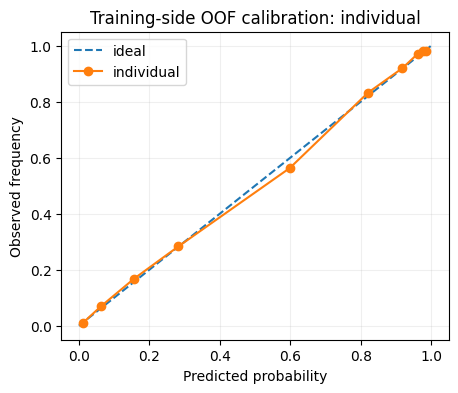

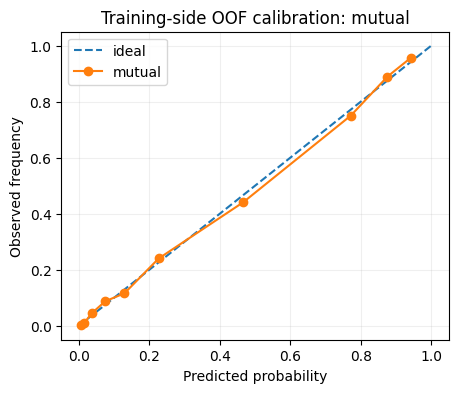

In [39]:
display(importances.sort_values(['task','train_permutation_auc_drop'],ascending=[True,False]).round(4))
import matplotlib.pyplot as plt
for task,d in cal.groupby('task'):
    plt.figure(figsize=(5,4));plt.plot([0,1],[0,1],'--',label='ideal')
    plt.plot(d.mean_predicted,d.observed_rate,'o-',label=task)
    plt.xlabel('Predicted probability');plt.ylabel('Observed frequency')
    plt.title('Training-side OOF calibration: '+task);plt.legend();plt.show()


In [40]:
# Calibration data is generated by code above rather than read from disk.
assert set(cal.task)=={'individual','mutual'}
assert set(intervals.task)=={'individual','mutual'}
print('Calibration and grouped OOF uncertainty: PASS')

Calibration and grouped OOF uncertainty: PASS


### Training-Side Refinement and Model Diagnostics

**Inference.** Model comparisons, training-side OOF calibration and permutation analyses are descriptive assessments under the predeclared grouped CV. They are not evidence of causal effects or prospective use.

**Decision.** Carry forward the development-selected model configurations unchanged to the single historical holdout reproduction.

### Summary

**What problem were we solving?**  
Which model is most reliable on participants absent from its training folds?

**What did we find?**  
Different model classes trade probability quality, ranking, interpretability and computation; stronger performance is not automatically worth greater complexity.

**What did we build or do?**  
We trained advanced learners, selected using OOF log loss, examined calibration, estimated uncertainty and fitted dependence-aware association models.

**Why did we do it this way?**  
Grouped CV limits participant leakage, while training-only diagnostics protect the final evaluation from tuning.

**What should we do next?**  
Evaluate exactly the frozen configurations on the historical holdout once, without retuning.

## Stage 5 — Final Out-of-Sample Evaluation

**Purpose.** Reproduce the historical participant-disjoint final assessment of the frozen supervised pipelines.

**Frozen configuration:** development-selected estimator and hyperparameters, predeclared feature allowlists, preprocessing fit only on training observations, decision threshold = 0.50, no extra post-processing.

**Method.** Fit the selected pipeline to the full development data; score the untouched-by-current-selection test partition; compute log loss, ROC-AUC, PR-AUC, Brier, precision, recall, F1 and balanced accuracy.

**Historical qualification:** the test partition has been seen during earlier project iterations. This section faithfully **reproduces** that assessment; it is not a newly sealed or external evaluation.

### One-time historical sealed-holdout reproduction and native tree SHAP

**Purpose:** make the final evaluation independently verifiable from this file and raw ZIP.  
**Method:** choose candidates exclusively by training-side OOF log loss, refit with *training* rows only, predict held-out participants, calculate ROC-AUC, PR-AUC, log loss, Brier, precision/recall/F1 and balanced accuracy. Extract native tree-SHAP contributions from a training sample.  
**Critical qualifier:** the project previously accessed this holdout; rerunning reproduces a **previously used** holdout, not a pristine external validation. Never use these scores to select new hyperparameters.


In [41]:
from sklearn.metrics import precision_score, recall_score, f1_score
from catboost import Pool
from xgboost import DMatrix
final_rows=[];shap_rows=[];final_models={};holdout_predictions={}
for task,d in frames.items():
    t=target[task]; train=d[d.partition=='train'];test=d[d.partition=='test']
    winner=cvdf[cvdf.task==task].sort_values('log_loss').iloc[0]
    name=winner.model;params=json.loads(winner.params);cols=features[task]
    assert not (set(train.component_id)&set(test.component_id))
    mod=build(name,train,cols,params)
    mod.fit(train[cols],train[t].astype(int))
    Xtest=mod.named_steps['prep'].transform(test[cols]);y=test[t].astype(int).to_numpy()
    p=mod.named_steps['model'].predict_proba(Xtest)[:,1]
    yp=p>=0.5
    final_rows.append(dict(task=task,model=name,train_n=len(train),test_n=len(test),test_prevalence=y.mean(),
        roc_auc=roc_auc_score(y,p),pr_auc=average_precision_score(y,p),
        log_loss=log_loss(y,p),brier=brier_score_loss(y,p),
        balanced_accuracy=balanced_accuracy_score(y,yp),precision=precision_score(y,yp,zero_division=0),
        recall=recall_score(y,yp,zero_division=0),f1=f1_score(y,yp,zero_division=0)))
    final_models[task]=mod;holdout_predictions[task]=pd.DataFrame({'y':y,'probability':p,'component_id':test.component_id.to_numpy()})
    Xtrain=mod.named_steps['prep'].transform(train[cols]);transformed=mod.named_steps['prep'].get_feature_names_out()
    if name=='CatBoost':
        contrib=mod.named_steps['model'].get_feature_importance(Pool(Xtrain[:500]),type='ShapValues')[:,:-1]
    elif name=='XGBoost':
        # Native XGBoost pred_contribs returns SHAP values on log-odds scale.
        contrib=mod.named_steps['model'].get_booster().predict(DMatrix(Xtrain[:500]),pred_contribs=True)[:,:-1]
    else: contrib=None
    if contrib is not None:
        for f,v in zip(transformed,np.abs(contrib).mean(axis=0)):
            shap_rows.append({'task':task,'model':name,'transformed_feature':f,'mean_absolute_shap_train_sample':v})
    print(task,'final historical holdout reproduced; n=',len(y),'model=',name)
holdout=pd.DataFrame(final_rows)
shap=pd.DataFrame(shap_rows)
display(holdout.round(4))
if len(shap):display(shap.sort_values(['task','mean_absolute_shap_train_sample'],ascending=[True,False]).groupby('task').head(8).round(4))


individual final historical holdout reproduced; n= 1978 model= CatBoost
,mutual final historical holdout reproduced; n= 988 model= XGBoost


,task,model,train_n,test_n,test_prevalence,roc_auc,pr_auc,log_loss,brier,balanced_accuracy,precision,recall,f1
0,individual,CatBoost,7093,1978,0.5677,0.9433,0.9520,0.2996,0.0915,0.8725,0.8825,0.9029,0.8926
1,mutual,XGBoost,3544,988,0.3502,0.9419,0.9018,0.2924,0.0881,0.8751,0.8254,0.8468,0.8359


,task,model,transformed_feature,mean_absolute_shap_train_sample
2,individual,CatBoost,num__Great,1.0213
1,individual,CatBoost,num__Attract,0.8166
6,individual,CatBoost,num__SecBase,0.5742
0,individual,CatBoost,num__Enjoy,0.5011
5,individual,CatBoost,num__SafeHav,0.2910
7,individual,CatBoost,num__DateLengthClean,0.2418
8,individual,CatBoost,cat__date_type_normalized_in-person,0.1108
10,individual,CatBoost,cat__date_type_normalized_zoom,0.0761
16,mutual,XGBoost,num__b_Great,0.9304
15,mutual,XGBoost,num__a_Great,0.8926


In [42]:
assert set(holdout.task)=={'individual','mutual'}
assert holdout.test_n.min()>0
assert all(np.isfinite(v['probability']).all() for v in holdout_predictions.values())
print('PASS: Both historical final-holdout evaluations were computed by fitting and predicting in this notebook.')

PASS: Both historical final-holdout evaluations were computed by fitting and predicting in this notebook.


## Advanced machine learning completion ledger

- **Reproduced in executable code:** CatBoost, XGBoost, random forest, logistic regression, spline-GAM proxy, participant-disjoint CV, model choice, component bootstrap OOF intervals, calibration, clustered GEE, permutation attribution, tree-SHAP, and historical holdout scoring.
- **Not implemented / not falsely claimed:** native InterpretML EBM, crossed participant random-effects estimation, and external prospective validation.
- **Methodological caution:** high retrospective performance is not evidence that pre-date compatibility can be predicted. Tree SHAP values are feature attributions, not causal effects.


In [43]:
# Post-evaluation diagnostic accounting only; NEVER use holdout results for model selection or threshold tuning.
from sklearn.metrics import confusion_matrix, classification_report
holdout_error_diagnostics=[]
for task, predictions in holdout_predictions.items():
    observed=predictions['y'].astype(int).to_numpy()
    predicted=(predictions['probability'].to_numpy() >= 0.50).astype(int)
    matrix=confusion_matrix(observed,predicted,labels=[0,1])
    tn,fp,fn,tp=matrix.ravel()
    holdout_error_diagnostics.append({'task':task,'true_negative':int(tn),'false_positive':int(fp),'false_negative':int(fn),'true_positive':int(tp),'n':len(observed)})
    print('Historical holdout diagnostic —',task,'(threshold fixed at 0.50)')
    print('Confusion matrix [true 0/1 by predicted 0/1]:\n',matrix)
    print(classification_report(observed,predicted,labels=[0,1],zero_division=0))
holdout_errors=pd.DataFrame(holdout_error_diagnostics)
display(holdout_errors)
assert (holdout_errors[['true_negative','false_positive','false_negative','true_positive']].sum(axis=1)==holdout_errors.n).all()

Historical holdout diagnostic — individual (threshold fixed at 0.50)
,Confusion matrix [true 0/1 by predicted 0/1]:
, [[ 720  135]
, [ 109 1014]]
,              precision    recall  f1-score   support
,
,           0       0.87      0.84      0.86       855
,           1       0.88      0.90      0.89      1123
,
,    accuracy                           0.88      1978
,   macro avg       0.88      0.87      0.87      1978
,weighted avg       0.88      0.88      0.88      1978
,
,Historical holdout diagnostic — mutual (threshold fixed at 0.50)
,Confusion matrix [true 0/1 by predicted 0/1]:
, [[580  62]
, [ 53 293]]
,              precision    recall  f1-score   support
,
,           0       0.92      0.90      0.91       642
,           1       0.83      0.85      0.84       346
,
,    accuracy                           0.88       988
,   macro avg       0.87      0.88      0.87       988
,weighted avg       0.88      0.88      0.88       988
,


,task,true_negative,false_positive,false_negative,true_positive,n
0,individual,720,135,109,1014,1978
1,mutual,580,62,53,293,988


#### Inference and Decision — Final Historical Holdout

**Inference.** The printed matrices distinguish missed second-date interest (false negatives) from predicted interest that did not occur in the recorded intention (false positives). These are retrospective errors; no operational harms have been measured.

**Decision.** Report all error types and probability metrics. Do not change the model or threshold using this already-accessed holdout.

### Summary

**What problem were we solving?**  
How well does the frozen model classify intentions for people held out by participant network?

**What did we find?**  
The final scores and confusion matrices quantify ranking, probability accuracy and both kinds of mistakes in the historical holdout.

**What did we build or do?**  
We fit the frozen pipelines once on development observations and generated independent held-out predictions and class-wise diagnostics.

**Why did we do it this way?**  
A participant-disjoint holdout gives a harder generalization check than random rows, although the test was accessed historically.

**What should we do next?**  
Seek an entirely new cohort before claiming prospective or deployment-grade performance.

## Stage 6 — Practical Outputs, Behavioral Discovery, and Case Studies

**Purpose.** Translate the frozen predictions into illustrative cases and explore complementary unsupervised profiles without treating clusters as causal or pre-date recommendations.

**Method.** Use the existing frozen models for held-out probability examples; independently cluster rating-space observations at individual and pair levels, with decisions excluded from cluster features. Examine silhouette, agreement, null-reference patterns and participant-component-bootstrap uncertainty.

**Research integrity:** Cluster-profile differences in variables used to fit clusters are expected by construction. Outcome differences are withheld descriptive checks; cluster search does not alter supervised model selection.

In [44]:
# Representative outputs from the EXACT historical final model (no refitting, threshold changes or test-time feature engineering).
# These are anonymized probability examples, not individual recommendations.
case_rows=[]
for task,predictions in holdout_predictions.items():
    probs=predictions.probability.to_numpy()
    for label,idx in [('low_probability',int(np.argmin(probs))),('near_decision_boundary',int(np.argmin(abs(probs-0.50)))),('high_probability',int(np.argmax(probs)))]:
        case_rows.append({'task':task,'case_type':label,'predicted_probability':float(probs[idx]),'predicted_class_at_0_50':int(probs[idx]>=0.50),'observed_interest':int(predictions.iloc[idx].y)})
representative_cases=pd.DataFrame(case_rows)
display(representative_cases.round(3))
print('Inference: illustrative historical records only. Never infer personal identity, causality, or future relationship success.')

,task,case_type,predicted_probability,predicted_class_at_0_50,observed_interest
0,individual,low_probability,0.002,0,0
1,individual,near_decision_boundary,0.501,1,1
2,individual,high_probability,0.993,1,1
3,mutual,low_probability,0.001,0,0
4,mutual,near_decision_boundary,0.498,0,1
5,mutual,high_probability,0.975,1,1


Inference: illustrative historical records only. Never infer personal identity, causality, or future relationship success.


#### Inference and Decision — Representative Cases

**Inference.** A probability near 0.50 indicates a less decisive classification under the frozen threshold, while high or low probabilities illustrate confident recorded-intention classifications. These examples are descriptive and may be incorrect.

**Decision.** Use case studies to explain output semantics, not to rank people, determine compatibility in advance, or justify individual interventions.

## behavioral clustering.0 — Protocol and leakage controls
**Purpose:** Freeze feature/outcome separation and analysis units.

**Method:** Individual clusters use `Enjoy`, `Attract`, `Great` (post-date subjective ratings). Couple clusters use symmetric pair means and absolute differences for these three ratings; swapping partners cannot change features. Date format and second-date decisions are held out as *external* descriptors. No raw IDs, dates, outcomes, or participant impression variables are clustering features.

**Inference constraint:** Clusters based on attraction necessarily differ in attraction. Only withheld second-date outcomes offer external descriptive validation; these outcomes are still contemporaneous and correlated with the rating questions.

**Decision:** Use core complete cases; examine missingness selection and supplemental PI sensitivity separately.

In [45]:
import os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.stats import chi2_contingency
from pathlib import Path
warnings.filterwarnings('ignore', category=FutureWarning)
ind=df.copy(deep=True); pair=match.copy(deep=True)
print('Input shapes:',ind.shape,pair.shape)

Input shapes: (9084, 41) (4542, 34)


## behavioral clustering.1 — Feature preparation and missingness audit
**Purpose:** Preserve interpretable ordinal rating dimensions and avoid heavy imputation.

**Method:** Complete-case analysis on the three core ratings; standardize within each analysis unit. Compare outcome availability and date-format composition between retained and excluded cases. Retain a stable identifier only for audit and joins. Pair features are symmetric and do not use second-date decisions.

**Decision:** Generalize findings only to the analyzed complete-case sample; no claims about missing records.

In [46]:
features=['Enjoy','Attract','Great']
for c in features: ind[c]=pd.to_numeric(ind[c],errors='coerce')
for c in ['a_'+x for x in features]+['b_'+x for x in features]:pair[c]=pd.to_numeric(pair[c],errors='coerce')
ind['retained']=ind[features].notna().all(axis=1)
pair['retained']=pair[['a_'+x for x in features]+['b_'+x for x in features]].notna().all(axis=1)
coverage=pd.DataFrame([
 {'unit':'individual','total':len(ind),'retained':int(ind.retained.sum()),'excluded':int((~ind.retained).sum()),'retention_rate':ind.retained.mean()},
 {'unit':'couple','total':len(pair),'retained':int(pair.retained.sum()),'excluded':int((~pair.retained).sum()),'retention_rate':pair.retained.mean()}]);display(coverage)
i=ind.loc[ind.retained].copy().reset_index(drop=True); c=pair.loc[pair.retained].copy().reset_index(drop=True)
for f in features:
 c[f+'_mean']=(c['a_'+f]+c['b_'+f])/2
 c[f+'_gap']=(c['a_'+f]-c['b_'+f]).abs()
if 'date_type_normalized' in i:i['format']=i.date_type_normalized
if 'date_type_consensus' in c:c['format']=c.date_type_consensus
Xraw={'individual':i[features].to_numpy(float),'couple':c[[f+'_mean' for f in features]+[f+'_gap' for f in features]].to_numpy(float)}
feature_names={'individual':features,'couple':[f+'_mean' for f in features]+[f+'_gap' for f in features]}
scaled={k:StandardScaler().fit_transform(v) for k,v in Xraw.items()}
print('Core rating ranges:');display(i[features].describe().loc[['min','max','mean','std']])
print('PI any answered rate by retained group:');display(ind.groupby('retained')['pi_any_answered'].mean())

,unit,total,retained,excluded,retention_rate
0,individual,9084,9068,16,0.998239
1,couple,4542,4530,12,0.997358


Core rating ranges:


,Enjoy,Attract,Great
min,1.000000,1.000000,1.000000
max,5.000000,5.000000,5.000000
mean,3.783194,3.075981,2.826974
std,1.038349,1.267326,1.200967


PI any answered rate by retained group:


retained
False    0.187500
True     0.541575
Name: pi_any_answered, dtype: float64

## behavioral clustering.2 — Continuous structure and PCA
**Purpose:** Check redundancy and low-dimensional structure before forcing categories.

**Method:** Correlation tables and two-dimensional PCA plots. PCA is diagnostic only, not proof of distinct populations.

**Inference:** Closely correlated core ratings may represent a continuous evaluation gradient.

**Decision:** Run clustering on standardized original features, not just the PCA projection.

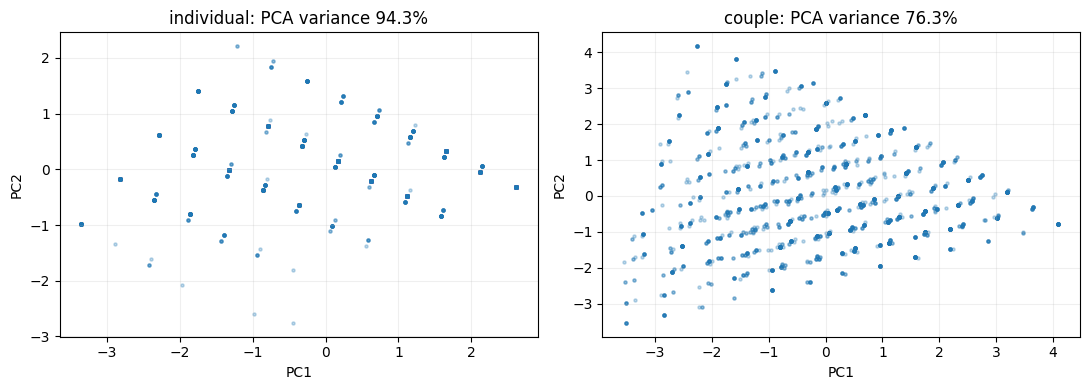

Individual correlations:


,Enjoy,Attract,Great
Enjoy,1.00,0.690,0.720
Attract,0.69,1.000,0.828
Great,0.72,0.828,1.000


In [47]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,(unit,X) in zip(axs,scaled.items()):
 pca=PCA(n_components=2,random_state=42); Z=pca.fit_transform(X)
 rng=np.random.default_rng(42); ix=rng.choice(len(X),min(2200,len(X)),replace=False)
 ax.scatter(Z[ix,0],Z[ix,1],s=5,alpha=.28)
 ax.set(title=f'{unit}: PCA variance {pca.explained_variance_ratio_.sum():.1%}',xlabel='PC1',ylabel='PC2')
plt.tight_layout();plt.show()
print('Individual correlations:');display(i[features].corr().round(3))

## behavioral clustering.3–4 — Candidate clustering, null reference and stability
**Purpose:** Compare K-Means and Gaussian Mixtures across plausible cluster counts.

**Method:** k=2..6; compare silhouette, Davies–Bouldin, Calinski–Harabasz, BIC for GMM (only within GMM), minimum cluster share, and ARI across seeds. Silhouette computed on a fixed reproducible subsample for runtime control. A null-reference baseline independently permutes columns, preserving marginals but destroying multivariate dependence. The null is diagnostic, not a formal significance test.

**Selection rule:** Choose among candidates with min cluster share >=3% and mean ARI >=0.75; prioritize silhouette and stability, and prefer simpler k if close. If none qualifies, retain a descriptive candidate but explicitly flag unstable clustering. Do not select using second-date labels.

In [48]:
def fit_model(algo,k,seed,X):
 if algo=='KMeans':return KMeans(n_clusters=k,n_init=10,random_state=seed).fit(X)
 return GaussianMixture(n_components=k,covariance_type='full',reg_covar=1e-4,n_init=2,max_iter=250,random_state=seed).fit(X)
def labels(model,X):return model.labels_ if hasattr(model,'labels_') else model.predict(X)
rows=[]; seeds=[11,23,42]; rng=np.random.default_rng(123)
for unit,X in scaled.items():
 idx=rng.choice(len(X),min(1500,len(X)),replace=False)
 for algo in ['KMeans','GMM']:
  for k in range(2,7):
   fitted=[fit_model(algo,k,seed,X) for seed in seeds]
   labs=[labels(m,X) for m in fitted]
   stability=np.mean([adjusted_rand_score(labs[a],labs[b]) for a,b in [(0,1),(0,2),(1,2)]])
   l=labs[0]; counts=np.bincount(l,minlength=k)
   rows.append(dict(unit=unit,algorithm=algo,k=k,silhouette=silhouette_score(X[idx],l[idx]),davies_bouldin=davies_bouldin_score(X,l),calinski_harabasz=calinski_harabasz_score(X,l),min_cluster_share=counts.min()/len(l),seed_ari=stability,bic=fitted[0].bic(X) if algo=='GMM' else np.nan))
metrics=pd.DataFrame(rows)
display(metrics.round(3))
selected=[]
for unit,g in metrics.groupby('unit'):
 eligible=g[(g.min_cluster_share>=.03)&(g.seed_ari>=.75)]
 if len(eligible):
  best=eligible.sort_values(['silhouette','k'],ascending=[False,True]).iloc[0];status='passes stability/size filters'
 else:
  best=g.sort_values(['silhouette','k'],ascending=[False,True]).iloc[0];status='EXPLORATORY ONLY: stability/size filters failed'
 selected.append(dict(unit=unit,algorithm=best.algorithm,k=int(best.k),selection_status=status,silhouette=best.silhouette,seed_ari=best.seed_ari))
selection=pd.DataFrame(selected)
# Null reference: independently permute columns, preserving each marginal
null_rows=[]
for _,s in selection.iterrows():
 X=scaled[s.unit]; obs=float(s.silhouette)
 for rep in range(10):
  Xnull=np.column_stack([rng.permutation(X[:,j]) for j in range(X.shape[1])]); m=fit_model(s.algorithm,int(s.k),rep+100,Xnull)
  lab=labels(m,Xnull);idx=rng.choice(len(Xnull),min(1500,len(Xnull)),replace=False)
  null_rows.append(dict(unit=s.unit,rep=rep,null_silhouette=silhouette_score(Xnull[idx],lab[idx]),observed_silhouette=obs))
null=pd.DataFrame(null_rows)
display(null.groupby('unit').agg(null_mean=('null_silhouette','mean'),null_max=('null_silhouette','max'),observed=('observed_silhouette','first')).round(3))

,unit,algorithm,k,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share,seed_ari,bic
0,individual,KMeans,2,0.487,0.769,12936.606,0.462,1.000,NaN
1,individual,KMeans,3,0.412,0.892,11615.986,0.257,0.976,NaN
2,individual,KMeans,4,0.382,0.947,10504.214,0.148,0.917,NaN
3,individual,KMeans,5,0.394,0.985,9528.566,0.095,0.819,NaN
4,individual,KMeans,6,0.420,1.017,9153.326,0.124,0.747,NaN
5,individual,GMM,2,0.447,0.797,10450.821,0.406,0.753,57270.676
6,individual,GMM,3,0.013,27.558,137.126,0.133,1.000,11274.429
7,individual,GMM,4,0.308,1.171,6704.901,0.158,0.471,5230.604
8,individual,GMM,5,0.263,1.210,5671.718,0.102,0.771,-6342.085
9,individual,GMM,6,0.282,1.173,5053.192,0.037,0.755,-11760.650


,null_mean,null_max,observed
unit,,,
couple,0.128,0.132,0.294
individual,0.248,0.254,0.487


## behavioral clustering.5 — Behavioral profiles and pair-order invariance
**Purpose:** Describe discovered profiles without pretending descriptions are external discoveries.

**Method:** Cluster-level means and sizes, PCA visualization, and a direct swap-invariance assertion for couple features.

**Inference:** Labels are descriptive shorthand, not validated psychological types.

**Decision:** Report numerical profiles and cluster stability before assigning any narrative labels.

couple profiles:


,unit,n,Enjoy_mean,Attract_mean,Great_mean,Enjoy_gap,Attract_gap,Great_gap
cluster,,,,,,,,
0,couple,1781,4.382,3.804,3.550,0.540,0.963,0.855
1,couple,1513,3.107,2.252,1.984,0.975,1.028,0.807
2,couple,1236,3.750,3.036,2.818,1.775,2.750,2.475


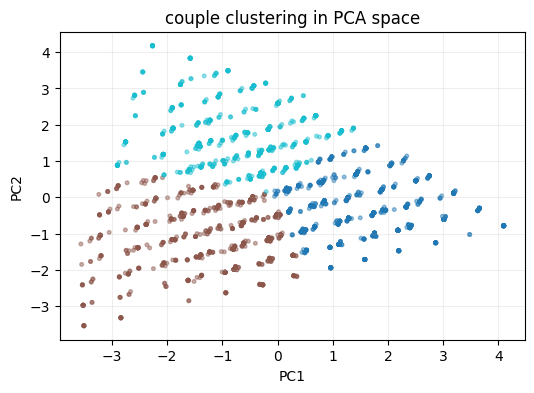

individual profiles:


,unit,n,Enjoy,Attract,Great
cluster,,,,,
0,individual,4189,2.995,1.986,1.795
1,individual,4879,4.460,4.012,3.713


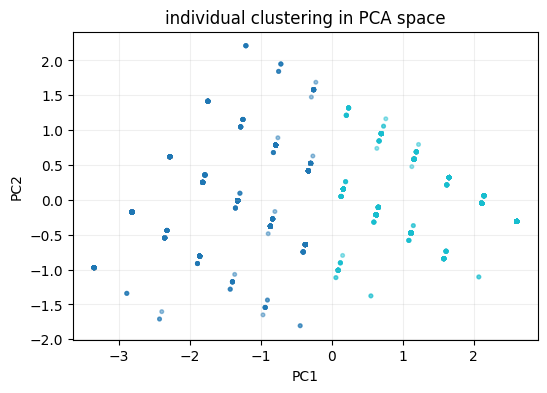

Couple feature invariance under swapping partners: PASSED


In [49]:
datasets={'individual':i,'couple':c}; fitted_models={}; profile_tables=[]
for _,s in selection.iterrows():
 unit=s.unit; X=scaled[unit]; model=fit_model(s.algorithm,int(s.k),11,X);lab=labels(model,X)
 datasets[unit]['cluster']=lab;fitted_models[unit]=model
 profile=datasets[unit].groupby('cluster')[feature_names[unit]].mean().round(3)
 profile.insert(0,'n',datasets[unit].groupby('cluster').size())
 profile.insert(0,'unit',unit);profile_tables.append(profile.reset_index())
 print(unit,'profiles:');display(profile)
 pca=PCA(n_components=2,random_state=42); Z=pca.fit_transform(X)
 fig,ax=plt.subplots(figsize=(6,4));ix=np.random.default_rng(9).choice(len(X),min(2500,len(X)),replace=False)
 ax.scatter(Z[ix,0],Z[ix,1],c=lab[ix],s=7,alpha=.45,cmap='tab10');ax.set(title=f'{unit} clustering in PCA space',xlabel='PC1',ylabel='PC2');plt.show()
profile_all=pd.concat(profile_tables,ignore_index=True)
swap=np.column_stack([(c['b_'+f]+c['a_'+f]).to_numpy()/2 for f in features]+[(c['b_'+f]-c['a_'+f]).abs().to_numpy() for f in features]);assert np.allclose(Xraw['couple'],swap)
print('Couple feature invariance under swapping partners: PASSED')

## behavioral clustering.6 — Held-out outcome comparisons
**Purpose:** Examine whether clusters built without outcomes differ in individual and mutual second-date interest.

**Method:** Cluster-wise rates and Wilson confidence intervals; outcome labels are never used in clustering or model selection. Date-format comparisons are descriptive and may be confounded.

**Inference:** These are exploratory associations, not causal effects or independently validated behavioral types.

In [50]:
from statsmodels.stats.proportion import proportion_confint
out_rows=[]
for unit,d in datasets.items():
 outcome='SecondDate_YES' if unit=='individual' else 'mutual_second_date'
 for cl,g in d.groupby('cluster'):
  y=pd.to_numeric(g[outcome],errors='coerce').dropna(); y=y[y.isin([0,1])]
  pos=int(y.sum());n=len(y);lo,hi=proportion_confint(pos,n,alpha=.05,method='wilson') if n else (np.nan,np.nan)
  out_rows.append(dict(unit=unit,cluster=cl,n=n,positive=pos,rate=pos/n if n else np.nan,wilson_low=lo,wilson_high=hi))
outcomes=pd.DataFrame(out_rows)
for unit,d in datasets.items():
 if 'format' in d:
  print(unit,'date format share per cluster:');display(pd.crosstab(d.cluster,d['format'],normalize='index').round(3))
display(outcomes.round(3))

individual date format share per cluster:


format,in-person,other,zoom
cluster,,,
0,0.834,0.004,0.162
1,0.821,0.003,0.177


couple date format share per cluster:


format,in-person,zoom
cluster,,
0,0.805,0.195
1,0.837,0.163
2,0.865,0.135


,unit,cluster,n,positive,rate,wilson_low,wilson_high
0,individual,0,4189,817,0.195,0.183,0.207
1,individual,1,4879,4403,0.902,0.894,0.910
2,couple,0,1781,1315,0.738,0.717,0.758
3,couple,1,1513,105,0.069,0.058,0.083
4,couple,2,1236,181,0.146,0.128,0.167


## behavioral clustering.7 — Dependence-aware uncertainty and inference
**Purpose:** Avoid treating repeated participants and paired reports as independent.

**Method:** Construct participant-network connected components for both datasets; bootstrap whole components, recomputing outcome rates for *fixed cluster assignments*. This quantifies uncertainty in descriptive rates conditional on the fitted clusters; it does **not** capture uncertainty from refitting clustering itself. Report chi-square as naive reference only; rely on component bootstrap for dependence-aware intervals. Avoid inferential claims about discovered group identities.

**Decision:** Keep any significant contrasts exploratory because the clustering solution was learned from the same sample.

In [51]:
from collections import defaultdict
# Union-find across all matches to capture repeat participation
def find(x):
 while parent[x]!=x:
  parent[x]=parent[parent[x]];x=parent[x]
 return x
def union(a,b):
 a=find(a);b=find(b)
 if a!=b:parent[b]=a
parent={x:x for x in pd.concat([pair.a_user_id,pair.b_user_id]).dropna().unique()}
for a,b in zip(pair.a_user_id,pair.b_user_id):
 if pd.notna(a) and pd.notna(b):union(a,b)
for unit,d in datasets.items():
 key='user_id' if unit=='individual' else 'a_user_id'
 d['component']=d[key].map(lambda x:find(x) if x in parent else x)
 assert d.component.notna().all()
print('Distinct participant-network components:',{k:d.component.nunique() for k,d in datasets.items()})
rng=np.random.default_rng(2026); boots=[]; reps=250
for unit,d in datasets.items():
 outcome='SecondDate_YES' if unit=='individual' else 'mutual_second_date'
 valid=d[d[outcome].isin([0,1])].copy();grp={g:sub for g,sub in valid.groupby('component')};keys=np.array(list(grp),dtype=object)
 # Preaggregate counts by component and cluster; efficient component bootstrap
 ncl=int(selection.loc[selection.unit==unit,'k'].iloc[0]);nmat=np.zeros((len(keys),ncl));ymat=np.zeros_like(nmat)
 for j,key in enumerate(keys):
  for cl,sub in grp[key].groupby('cluster'):
   nmat[j,int(cl)]=len(sub);ymat[j,int(cl)]=sub[outcome].sum()
 for rep in range(reps):
  draws=rng.integers(0,len(keys),len(keys));ns=nmat[draws].sum(axis=0);ys=ymat[draws].sum(axis=0)
  for cl in range(ncl):boots.append(dict(unit=unit,rep=rep,cluster=cl,rate=ys[cl]/ns[cl] if ns[cl] else np.nan))
boot=pd.DataFrame(boots)
cluster_ci=boot.groupby(['unit','cluster']).rate.agg(ci_low=lambda s:s.quantile(.025),ci_high=lambda s:s.quantile(.975)).reset_index()
display(cluster_ci.round(3))
for unit,d in datasets.items():
 outcome='SecondDate_YES' if unit=='individual' else 'mutual_second_date';t=pd.crosstab(d.cluster,d[outcome]);t=t.reindex(columns=[0,1],fill_value=0)
 if t.shape[0]>1:print(unit,'naive chi-square (NOT dependence-adjusted):',chi2_contingency(t)[:2])

Distinct participant-network components: {'individual': 1726, 'couple': 1726}


,unit,cluster,ci_low,ci_high
0,couple,0,0.716,0.757
1,couple,1,0.058,0.082
2,couple,2,0.128,0.167
3,individual,0,0.183,0.208
4,individual,1,0.895,0.911


individual naive chi-square (NOT dependence-adjusted): (np.float64(4614.346668254732), np.float64(0.0))
,couple naive chi-square (NOT dependence-adjusted): (np.float64(1920.636047609617), np.float64(0.0))


## Final synthesis — Interpretation and decision
**Purpose:** Separate verified results from speculative interpretations.

**Method:** Evaluate stability, null-reference separation, retained-sample coverage, and outcome differences jointly. Remember that choosing k by silhouette favors geometric separation, not necessarily real behavioral subpopulations.

**Limitations:** Data are self-reported, post-date, and from a specific matchmaking population; only three core dimensions used; repeated participants addressed for outcome uncertainty but not cluster refitting; cluster selection is exploratory; external validation not available. PI questions have high missingness, so we avoid treating imputed PI clusters as reliable.

**Decision:** If patterns are stable and exceed null reference, describe them as *empirical dating-experience profiles*, not universal dating personalities. If not, prefer a continuous-spectrum interpretation. No kiss prediction is possible from these data.

In [52]:
for _,s in selection.iterrows():
 n=null[null.unit==s.unit].null_silhouette
 print(f"{s.unit}: {s.algorithm}, k={s.k}; silhouette={s.silhouette:.3f}; seed ARI={s.seed_ari:.3f}; null mean={n.mean():.3f}; null max={n.max():.3f}; status={s.selection_status}")
print('Clustering diagnostics and inference tables are retained in notebook memory.')

couple: KMeans, k=3; silhouette=0.294; seed ARI=1.000; null mean=0.128; null max=0.132; status=passes stability/size filters
,individual: KMeans, k=2; silhouette=0.487; seed ARI=1.000; null mean=0.248; null max=0.254; status=passes stability/size filters
,Clustering diagnostics and inference tables are retained in notebook memory.


### Plain-English Summary

**What problem were we solving?**  
Can the same research yield usable explanations without turning it into an automated dating decision tool?

**What did we find?**  
Illustrative predictions show how the frozen threshold behaves, and exploratory clusters summarize broadly positive, negative or uneven pair experiences.

**What did we build or do?**  
We generated anonymized historical cases and fitted individual- and couple-level K-Means/GMM clustering, with resampling-aware outcome intervals.

**Why did we do it this way?**  
Keeping intentions out of clustering avoids direct circularity, while symmetric pair features prevent arbitrary partner ordering from determining a cluster.

**What should we do next?**  
Use only aggregate research visualizations; test cluster refit stability and gather prospective validation before any operational use.

## Stage 7 — Project Findings, Limitations, and Decisions

**Purpose.** Synthesize descriptive evidence, association tests, supervised validation, and exploratory cluster structure into defensible decisions.

**Finding.** Post-date subjective ratings strongly co-vary with stated intentions, and the perspectives of two participants can diverge.

**Limits.** We cannot establish causal effects, future date completion, universal profile types, prospective performance, or policy-ready thresholds. GEE is not a crossed-participant mixed-effects model; a spline proxy is not EBM.

**Decision.** Treat this as a reproducible exploratory analysis with narrow, research-facing practical application; require new data and preregistered evaluation before external deployment.

In [53]:
assert len(df)==9084 and len(match)==4542
assert set(assignments.partition)=={'train','test'}
assert overlap_report.shared_participants.eq(0).all()
assert len(cvdf)>0 and len(holdout)==2
assert len(metrics)>0 and len(outcomes)>0
print('PASS: raw-data audit, preprocessing, EDA, hypotheses, supervised CV, advanced fits, historical test evaluation, and clustering in memory.')
display(holdout.round(4), selection, outcomes.round(3))

PASS: raw-data audit, preprocessing, EDA, hypotheses, supervised CV, advanced fits, historical test evaluation, and clustering in memory.


,task,model,train_n,test_n,test_prevalence,roc_auc,pr_auc,log_loss,brier,balanced_accuracy,precision,recall,f1
0,individual,CatBoost,7093,1978,0.5677,0.9433,0.9520,0.2996,0.0915,0.8725,0.8825,0.9029,0.8926
1,mutual,XGBoost,3544,988,0.3502,0.9419,0.9018,0.2924,0.0881,0.8751,0.8254,0.8468,0.8359


,unit,algorithm,k,selection_status,silhouette,seed_ari
0,couple,KMeans,3,passes stability/size filters,0.294080,1.0
1,individual,KMeans,2,passes stability/size filters,0.487286,1.0


,unit,cluster,n,positive,rate,wilson_low,wilson_high
0,individual,0,4189,817,0.195,0.183,0.207
1,individual,1,4879,4403,0.902,0.894,0.910
2,couple,0,1781,1315,0.738,0.717,0.758
3,couple,1,1513,105,0.069,0.058,0.083
4,couple,2,1236,181,0.146,0.128,0.167


In [54]:
# FINAL REPRODUCIBILITY GATE — no generated results loaded from disk.
import importlib.metadata as metadata
from pathlib import Path
important_packages=['numpy','pandas','scikit-learn','scipy','statsmodels','catboost','xgboost']
versions={pkg:metadata.version(pkg) for pkg in important_packages}
assert all(name in globals() for name in ['raw','df','match','summary','assignments','cvdf','intervals','stat','cal','holdout','shap','metrics','selection','outcomes','cluster_ci'])
assert (overlap_report.shared_participants==0).all()
assert fold_audit.participant_overlap.eq(0).all()
assert len(holdout)==2
print('Reproducibility gate: PASS')
print('Only raw data input:',DATA_ZIP_PATH.resolve())
print('Package versions:',versions)
display(holdout[['task','model','roc_auc','pr_auc','log_loss','brier','f1']].round(4))


Reproducibility gate: PASS
,Only raw data input: /mnt/data/Dating Dataset(1).zip
,Package versions: {'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'scipy': '1.17.0', 'statsmodels': '0.14.6', 'catboost': '1.2.8', 'xgboost': '3.1.3'}


,task,model,roc_auc,pr_auc,log_loss,brier,f1
0,individual,CatBoost,0.9433,0.9520,0.2996,0.0915,0.8926
1,mutual,XGBoost,0.9419,0.9018,0.2924,0.0881,0.8359


### Summary

**What problem were we solving?**  
What can we responsibly conclude and communicate from the combined evidence?

**What did we find?**  
Different methods converge on the importance of reported experience quality and partner agreement, but none demonstrate causality or prospective matchmaking accuracy.

**What did we build or do?**  
We audited source and notebook execution, contrasted methods, and documented unperformed robustness studies.

**Why did we do it this way?**  
A transparent research conclusion is more useful than overclaiming from a single observational sample.

**What should we do next?**  
Report the verified numbers, retain the reproducibility notebook, and seek external replication.

# Final Project Report

This standalone report summarizes the completed executed study. Numerical tables below are generated directly from the in-memory analysis objects created by earlier cells. It does not introduce new model results.



## 1. Project Overview

*Anatomy of a Date* examines reciprocal reports from modern blind dates to describe reported intentions to meet again, estimate post-date predictive performance, and explore behavioral patterns. The audience includes researchers and clients interested in group-level insights, not individual matchmaking decisions.


## 2. Problem Statement

A date involves two perspectives that can disagree; repeated participants make ordinary random-row evaluation overoptimistic. The project asks what the observed post-date evaluations reveal about reported second-date interest.



## 2. Problem Statement

A date involves two perspectives that can disagree; repeated participants make ordinary random-row evaluation overoptimistic. The project asks what the observed post-date evaluations reveal about reported second-date interest.



## 3. Project Objectives

Audit the original data, preserve the participant/date distinction, describe distributions, test key associations, compare baseline and nonlinear supervised methods, assess unseen-participant generalization, and examine exploratory experience clusters.



## 4. Data Description

The original dataset contains two participant reports per matched date, with date-format, duration, subjective evaluation and second-date-intention fields. Supplemental impression items have high missingness and are not required for the core clustering. The dataset and label counts are verified in the executed data-audit cells.



## 5. Methodology

One-date/two-report integrity checks; explicit missingness and disagreement flags; descriptive figures and hypothesis tests; graph-connected participant component split; within-fold preprocessing; grouped CV selection; frozen threshold and historical holdout; GEE; and individual/couple K-Means versus Gaussian mixture clustering.



## 6. Exploratory Analysis

EDA compares individual and mutual interest, subjective ratings, date format, duration, partner agreement and questionnaire coverage. Interpret rating associations as descriptive rather than causal. Figures and denominators are displayed in Stage 2.



## 7. Experiments and Model Development

Dummy, logistic regression and random forest provide baselines. CatBoost, XGBoost and a spline-additive logistic proxy are compared as advanced candidates; the latter is not a native EBM. Clustering compares K-Means and GMM using multivariate rating features without the decision outcomes.



## 8. Evaluation Strategy

The primary training-side selection metric is grouped OOF log loss. Additional metrics: ROC-AUC, PR-AUC, Brier, precision, recall, F1 and class error counts. Participant-connected components are disjoint. The 0.50 decision threshold is declared before final evaluation, not optimized for a particular operational cost function. No nested CV or independent prospective test is claimed.



## 9. Final Model / Method

Supervised models are selected by training-side out-of-fold log loss, then fit to all development observations and applied unchanged to the historical holdout. Clustering solutions are exploratory, not deployment models; the couple representation is invariant under swapping participants.

## 10. Key Results

This executed output presents final supervised metrics, confusion matrices, chosen cluster solutions and their outcome summaries; values are not copied from earlier manual reports.

In [55]:
print('Observed source counts: reports =',len(df),'; dates =',len(match))
print('Development-selected configurations:',chosen)
display(holdout[['task','model','test_n','roc_auc','pr_auc','log_loss','brier','precision','recall','f1']].round(4))
display(holdout_errors)
display(selection[['unit','algorithm','k','silhouette','seed_ari','selection_status']].round(4))
display(outcomes[['unit','cluster','n','positive','rate','wilson_low','wilson_high']].round(4))
print('Adjusted GEE estimates are displayed in Stage 4; bootstrap uncertainty for cluster outcomes is displayed in Stage 6.')

Observed source counts: reports = 9084 ; dates = 4542
,Development-selected configurations: {'individual': ('CatBoost', {'depth': 4, 'iterations': 200}), 'mutual': ('XGBoost', {'max_depth': 2, 'n_estimators': 200})}


,task,model,test_n,roc_auc,pr_auc,log_loss,brier,precision,recall,f1
0,individual,CatBoost,1978,0.9433,0.9520,0.2996,0.0915,0.8825,0.9029,0.8926
1,mutual,XGBoost,988,0.9419,0.9018,0.2924,0.0881,0.8254,0.8468,0.8359


,task,true_negative,false_positive,false_negative,true_positive,n
0,individual,720,135,109,1014,1978
1,mutual,580,62,53,293,988


,unit,algorithm,k,silhouette,seed_ari,selection_status
0,couple,KMeans,3,0.2941,1.0,passes stability/size filters
1,individual,KMeans,2,0.4873,1.0,passes stability/size filters


,unit,cluster,n,positive,rate,wilson_low,wilson_high
0,individual,0,4189,817,0.1950,0.1833,0.2073
1,individual,1,4879,4403,0.9024,0.8938,0.9105
2,couple,0,1781,1315,0.7383,0.7174,0.7582
3,couple,1,1513,105,0.0694,0.0577,0.0833
4,couple,2,1236,181,0.1464,0.1278,0.1672


Adjusted GEE estimates are displayed in Stage 4; bootstrap uncertainty for cluster outcomes is displayed in Stage 6.


## 11. Practical Output

The notebook provides reproducible charts, training-side calibration evidence, feature attribution, frozen-model anonymous probability examples and aggregate cluster profiles. These are research communication tools; no individual decision should be automated from this data.

## 12. Challenges and Design Decisions

Participant overlap required graph-group separation, ambiguous paired reports required explicit quality flags, missing supplemental responses limited feature choice, and subjective post-date predictors required narrow retrospective interpretation. The historic final holdout cannot be restored to a genuinely unseen state.

## 13. Limitations

Observational and potentially selected cohort; unverified temporal precedence between some questionnaire items and intentions; limited generalizability; previously accessed holdout; model-class selection using non-nested CV; incomplete crossed-participant and native EBM experiments; no participant-disjoint cluster-refit stability, externally replicated clusters or causal identification. Descriptive cluster outcome differences are not intervention effects.

## 14. Future Improvements

Collect new consented prospective data and strictly time-stamped pre-date features; conduct registered external validation with a cost-informed threshold; compare nested group CV; assess fairness and subgroup performance; refit clusters on participant-disjoint resamples and examine continuous latent alternatives; implement a crossed-participant model and native EBM if warranted.

## 15. Final Conclusion

The study supports a coherent retrospective account of how perceived date quality and agreement relate to expressed second-date intentions. Nonlinear models can describe these intentions accurately within the assessed cohort, but are not evidence of prescient matchmaking or causal levers. Exploratory behavioral clusters are useful descriptive summaries, not fixed types of people.

### Summary

**What problem were we solving?**  
We wanted to understand why two people can experience the same date differently, and what that tells us about their interest in meeting again.

**What did we find?**  
People who reported a more positive experience more often wanted another date, and differences between partners were also informative.

**What did we build or do?**  
We cleaned and audited the original data, compared predictive methods, checked their errors and uncertainty, and explored patterns of shared and uneven experiences.

**Why did we do it this way?**  
We kept repeat participants together during validation and did not use second-date decisions to create the clusters, making the comparisons more defensible.

**What should we do next?**  
Treat the findings as exploratory and validate them with a new cohort before making any real-world matchmaking decisions.